#**Imersão em IA Industrial: LLMs e Engenharia de Prompt na Manutenção Preditiva**
Neste notebook vamos construir, em 3 blocos, um painel de manutenção preditiva
para uma fresadora industrial, usando os dados sintéticos públicos do
**AI4I 2020** (UCI Machine Learning Repository), e conectá-lo a uma LLM por meio
de RAG e engenharia de prompt:

* Bloco 1 — LLM & Visão Geral: primeiro contato com o modelo de linguagem (Exemplos A e B)
* Bloco 2 — RAG: mecanismos de consulta à documentação técnica da planta (PDFs)
* Bloco 3 — Engenharia de Prompt: implementação do sistema industrial emulado (planta AI4I 2020),
  construção dos prompts de instrução e aplicação final com o painel (Gradio)

-------------------------------------------------------------------------------
Antes de começar
-------------------------------------------------------------------------------
No Colab, adicione o segredo (ícone de chave 🔑 na barra lateral esquerda):

  - GROQ_API_KEY  → chave da API da Groq (obrigatório)

Algumas instruções:

* Os PDFs da planta são baixados automaticamente no Bloco 2 e o dataset AI4I 2020
no Bloco 3, direto do repositório da UCI — não é preciso enviar nada manualmente.

* Ao final do notebook, a aplicação proposta do Bloco 3 abre o painel de monitoramento com um link
público, gerado automaticamente pelo Gradio.

## Bloco 1 — LLM & Visão Geral

Compreensão de LLM e aplicações.

### Prática I — Executando o código

1. Acesso ao material
2. Cadastro da API Groq: crie uma chave gratuita em console.groq.com e salve
   como segredo GROQ_API_KEY no Colab (é o único segredo necessário)
3. Executando o código

#Exemplo A

Configuração do modelo LLM com chamada direta no terminal de programação.

In [1]:
!pip install -q langchain langchain-groq

from langchain_groq import ChatGroq
from google.colab import userdata

GROQ_API_KEY = userdata.get('GROQ_API_KEY')  # confira o nome do segredo no Colab
# coloque o mesmo nome entre ' ' que você definiu no secret

llm = ChatGroq(
    model="openai/gpt-oss-20b", # teste o openai/gpt-oss-20b openai/gpt-oss-120b
    temperature=0.1,  # 0 a 1: quanto maior, mais criativa a resposta
    api_key=GROQ_API_KEY,
)

resp_test = llm.invoke("como a inteligência artificial é usada na manutenção preditiva de máquinas industriais?") # varie as perguntas
print(resp_test.content)

## Inteligência Artificial na Manutenção Preditiva de Máquinas Industriais

A manutenção preditiva (MP) visa identificar falhas antes que elas ocorram, permitindo intervenções programadas e evitando paradas inesperadas. A inteligência artificial (IA) tem se tornado o “cérebro” dessa abordagem, transformando grandes volumes de dados de sensores em insights acionáveis. A seguir, detalhamos como a IA é empregada, desde a coleta de dados até a tomada de decisão.

---

### 1. Coleta de Dados – O “Coração” da MP

| Fonte | Tipo de dado | Exemplo |
|-------|--------------|---------|
| **Sensores de vibração** | Amplitude, frequência | Vibração de eixo de motor |
| **Temperatura** | Temperatura de superfície, interna | Termopar em turbinas |
| **Pressão** | Pressão de óleo, gás | Pressão em bombas |
| **Corrente elétrica** | Corrente, tensão | Corrente de motores elétricos |
| **Acústica** | Sons, ruídos | Sons de desgaste de rolamentos |
| **Imagens** | Visão computacional | Fotografia de peç

#Exemplo B

Agora a LLM recebe uma **ficha técnica** da máquina como contexto fixo, na
mensagem de sistema (system prompt). Esse é o primeiro passo de engenharia de
prompt: dar à LLM o contexto que ela não tem. A fresadora do AI4I 2020 tem cinco
modos de falha, cada um definido por uma regra física conhecida. O gráfico
abaixo mostra a região de operação segura em relação à potência mecânica
(P = torque × velocidade angular): fora da faixa de 3500 W a 9000 W ocorre
falha de potência (PWF).

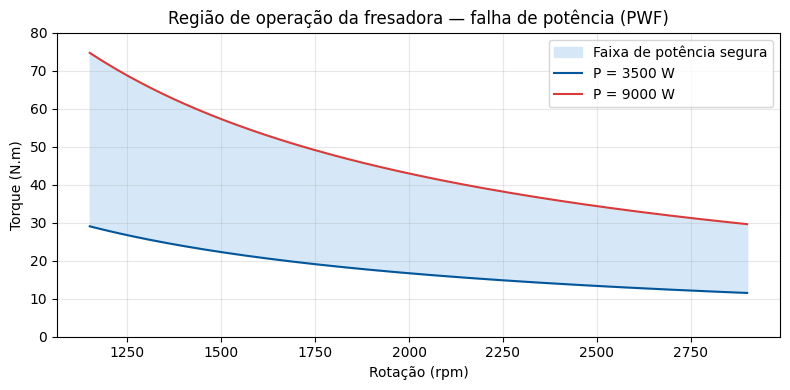

Para verificar se a máquina pode entrar em falha de potência (PWF) precisamos calcular a potência real a partir do torque e da rotação, e comparar com o intervalo permitido (3500 W ≤ P ≤ 9000 W).

**1. Converta a rotação de rpm para rad/s**

ω = (rpm x 2 π) / 60

ω = (1400 x 2 x 3,1416) / 60

ω = (1400 x 6,2832) / 60

ω = 8795,28 / 60 ≈ 146,6 rad/s

**2. Calcule a potência**

P = torque x ω

P = 60 N.m x 146,6 rad/s

P ≈ 8796 W

**3. Compare com a faixa de falha**

A regra PWF diz que a falha ocorre quando a potência está fora de 3500 W a 9000 W. 
8796 W está dentro desse intervalo (3500 ≤ 8796 ≤ 9000), portanto a máquina **não está em risco de falha de potência** neste instante.

> **Observação prática**: no dataset a distribuição normal do torque tem média 40 N.m e desvio 10 N.m, então um torque de 60 N.m já está acima da média. Se a rotação aumentasse ou o torque aumentasse ainda mais, a potência poderia ultrapassar 9000 W e a falha de potência seria acionada.

In [2]:
import re

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from langchain_core.messages import HumanMessage, SystemMessage

# ---- Ficha técnica da fresadora (AI4I 2020) ----
ficha_maquina = """
Ativo: fresadora industrial (dataset sintético AI4I 2020, UCI, Matzka 2020)
Variáveis medidas a cada ciclo:
  - Tipo de produto: L (60% dos ciclos), M (30%), H (10%) — variantes de qualidade
  - Temperatura do ar [K]: passeio aleatório com desvio padrão de 2 K em torno de 300 K
  - Temperatura do processo [K]: temperatura do ar + 10 K, desvio padrão de 1 K
  - Rotação [rpm]: calculada a partir de potência de 2860 W, com ruído normal
  - Torque [N.m]: distribuição normal em torno de 40 N.m, desvio de 10 N.m, sem valores negativos
  - Desgaste da ferramenta [min]: as variantes H/M/L somam 5/3/2 min por ciclo

Modos de falha (regras de geração do dataset):
  - TWF (desgaste da ferramenta): troca ou falha em tempo aleatório entre 200 e 240 min de desgaste
  - HDF (dissipação de calor): diferença entre temperatura do processo e do ar < 8,6 K E rotação < 1380 rpm
  - PWF (potência): potência = torque x rotação (rad/s) fora da faixa 3500 W a 9000 W
  - OSF (sobrecarga): desgaste x torque > 11000 min.N.m (L), 12000 (M) ou 13000 (H)
  - RNF (aleatória): 0,1% de chance por ciclo, independente dos parâmetros

Resumo: 10000 registros, 339 falhas (3,39%) — classes fortemente desbalanceadas.
"""

# ---- Região de operação por potência ----
rotacao = np.linspace(1150, 2900, 300)
omega = rotacao * 2 * np.pi / 60
torque_min = 3500 / omega
torque_max = 9000 / omega

plt.figure(figsize=(8, 4))
plt.fill_between(rotacao, torque_min, torque_max, color="#D6E8F8", label="Faixa de potência segura")
plt.plot(rotacao, torque_min, color="#025699", lw=1.5, label="P = 3500 W")
plt.plot(rotacao, torque_max, color="#D93A3A", lw=1.5, label="P = 9000 W")
plt.title("Região de operação da fresadora — falha de potência (PWF)")
plt.xlabel("Rotação (rpm)"); plt.ylabel("Torque (N.m)")
plt.ylim(0, 80); plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

# ---- Limpeza de LaTeX ----
# Mesmo pedindo texto simples, alguns modelos (como o gpt-oss) escrevem fórmulas em
# LaTeX por hábito. Uma instrução no prompt reduz, mas não garante; por isso a
# resposta passa por uma limpeza antes de ser exibida (pós-processamento).
_SIMBOLOS_LATEX = {
    r"\times": "x", r"\cdot": "x", r"\approx": "≈", r"\neq": "≠", r"\leq": "≤", r"\geq": "≥",
    r"\le": "≤", r"\ge": "≥", r"\pi": "π", r"\Delta": "Δ", r"\omega": "ω", r"\rightarrow": "→",
    r"\to": "→", r"\Rightarrow": "⇒", r"\pm": "±", r"\%": "%", r"\degree": "°", r"\circ": "°",
}


def _grupo(x):
    x = x.strip()
    return f"({x})" if re.search(r"[\s+\-x×/]", x) else x


def limpar_latex(texto):
    """Converte fórmulas em LaTeX (que algumas LLMs usam mesmo quando pedimos texto simples)
    para texto simples legível no Colab e no Gradio."""
    t = texto
    # delimitadores de equação: \[ \], \( \), $$ $$, $ $
    t = re.sub(r"\\\[\s*(.*?)\s*\\\]", r"\n\n\1\n\n", t, flags=re.S)
    t = re.sub(r"(?<!\\)\[\s*([^\[\]\n]*\\[A-Za-z][^\[\]\n]*?)\s*\]", r"\n\n\1\n\n", t)  # [ \frac.. ] sem a barra
    t = re.sub(r"\\\(\s*(.*?)\s*\\\)", r"\1", t, flags=re.S)
    t = re.sub(r"\$\$\s*(.*?)\s*\$\$", r"\n\n\1\n\n", t, flags=re.S)
    t = re.sub(r"(?<!\w)\$(?!\s)([^$\n]+?)(?<!\s)\$(?!\w)", r"\1", t)
    # comandos com argumento: \text{..}, \mathrm{..}, \frac{a}{b}, \sqrt{x}
    for _ in range(4):  # repete para resolver comandos aninhados
        t = re.sub(r"\\(?:text|mathrm|textbf|mathbf|operatorname|mbox)\s*\{([^{}]*)\}", r"\1", t)
        t = re.sub(r"\\[dt]?frac\s*\{([^{}]*)\}\s*\{([^{}]*)\}", lambda m: f"{_grupo(m[1])} / {_grupo(m[2])}", t)
        t = re.sub(r"\\sqrt\s*\{([^{}]*)\}", r"√(\1)", t)
    for comando, simbolo in sorted(_SIMBOLOS_LATEX.items(), key=lambda x: -len(x[0])):
        t = re.sub(re.escape(comando) + r"(?![A-Za-z])", simbolo, t)
    t = re.sub(r"\\(?:left|right|displaystyle|quad|qquad)(?![A-Za-z])", "", t)
    t = re.sub(r"\\[,;:! ]", " ", t)          # espaçamentos do LaTeX
    t = re.sub(r"\^\{([^{}]*)\}", r"^\1", t)  # x^{2} -> x^2
    t = re.sub(r"_\{([^{}]*)\}", r"_\1", t)   # x_{ar} -> x_ar
    t = t.replace("{,}", ",").replace("{.}", ".")      # 310{,}2 -> 310,2
    t = re.sub(r"Δ (?=[A-Za-z])", "Δ", t)             # Δ T -> ΔT
    t = re.sub(r"\n[ \t]+(?=\n)", "\n", t)
    t = re.sub(r"\n\n[ \t]+", "\n\n", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    t = re.sub(r"(?<=\S)[ \t]{2,}", " ", t)
    return t.strip()


SYSTEM_PROMPT = f"""Você é um engenheiro de manutenção e confiabilidade e também professor.
Responda em português, de forma didática e completa, explicando o raciocínio por trás da
resposta, não só o resultado. Sempre que fizer sentido, relacione o conceito perguntado com a
ficha técnica abaixo e explique o que ela significa na prática. Nunca invente números; use
apenas os dados fornecidos.

{ficha_maquina}

Estruture a resposta em 1 a 3 parágrafos (ou tópicos, se for mais claro), evitando respostas
de uma linha só, mesmo que a pergunta seja simples.

REGRA DE FORMATAÇÃO (obrigatória): a resposta é exibida como texto simples, sem suporte a LaTeX.
Escreva cálculos assim:
  ω = 1500 x 2 x 3,1416 / 60 = 157,1 rad/s
  P = 40 x 157,1 = 6283 W
Use x para multiplicação, / para divisão, ≈ para aproximação e π, Δ, ≤, ≥ como caracteres.
É proibido usar \\frac, \\text, \\times, \\approx ou qualquer comando com barra invertida,
e também os delimitadores \\[ \\], \\( \\) e $ $.
"""

# ---- Conversa ----
# O histórico é a "memória" da conversa: a cada pergunta, a mensagem de sistema
# e todas as trocas anteriores são reenviadas à LLM (janela de contexto).
historico = [SystemMessage(SYSTEM_PROMPT)]

def perguntar(pergunta):
    historico.append(HumanMessage(pergunta))
    resposta = llm.invoke(historico)
    resposta.content = limpar_latex(resposta.content)  # garante texto simples, mesmo se a LLM usar LaTeX
    historico.append(resposta)
    display(Markdown(resposta.content))

def nova_conversa():
    del historico[1:]


perguntar("Uma máquina com torque de 60 N.m a 1400 rpm está em risco de falha de potência? Mostre o cálculo.") # varie as perguntas

# "Por que o modo HDF depende da diferença entre temperatura do processo e do ar?"
# "Qual modo de falha é mais difícil de prever com machine learning? Por quê?"
# "Por que um dataset com 3,39% de falhas é um problema para treinar um classificador?"
# "Qual a diferença entre o limite de sobrecarga (OSF) dos produtos L, M e H?"

## Bloco 2 — RAG: mecanismos de consulta

No Exemplo B, tudo o que a LLM sabe sobre a fresadora está escrito dentro do
prompt, na ficha técnica. Perguntas como "qual o procedimento da equipe em um
alarme de sobrecarga?" ou "por que o sistema usa divisão temporal dos dados?"
dependem de informações que estão nos três PDFs da planta:

| Arquivo | Conteúdo |
|---|---|
| 01_planta_fresadora_FR01.pdf | Cenário, variantes de produto, tags do painel e arquitetura de dados |
| 02_modos_de_falha_FR01.pdf | Regras, exemplos numéricos e consistência dos rótulos de cada modo de falha |
| 03_sistema_monitoramento_PdM01.pdf | Modelos, níveis de alarme, desempenho e procedimentos de manutenção |

Colar os PDFs inteiros no prompt não é uma boa solução: o prompt fica longo e
caro, e a informação relevante se perde no meio do texto. O **RAG
(Retrieval-Augmented Generation)** resolve isso buscando apenas os trechos
relevantes para cada pergunta.

### Prática III — Construção do banco de informações sobre a planta

  1. Leitura de todos os PDFs disponíveis em /content/.
  2. Divisão de cada documento em chunks, com sobreposição entre eles.
  3. Conversão de cada trecho em embedding e indexação desses vetores em um
     banco vetorial (FAISS).
  4. No momento da pergunta, busca dos trechos mais relevantes e envio
     apenas deles para a LLM gerar a resposta.

A célula abaixo baixa os PDFs do repositório (se preferir, envie-os pela aba
de arquivos do Colab para /content/) e monta a base de conhecimento. Na
aplicação final (Bloco 3), a opção **Consultar a documentação da planta (RAG)**
acrescenta os trechos encontrados ao prompt. A decisão de quando consultar a
documentação ainda é nossa; o agente que decide sozinho fica para a próxima aula.

In [3]:
!pip install -q faiss-cpu langchain-community langchain-huggingface langchain-text-splitters pymupdf

import urllib.request
from pathlib import Path

BASE_DIR = Path("/content")

# PDFs baixados direto do GitHub (sem git clone)
RAW_URL = "https://raw.githubusercontent.com/laismngueira/minicurso-embrapii/main/versao_pdm"
ARQUIVOS_APOIO = [
    "01_planta_fresadora_FR01.pdf",
    "02_modos_de_falha_FR01.pdf",
    "03_sistema_monitoramento_PdM01.pdf",
]

print("Documentação da planta:")
for nome in ARQUIVOS_APOIO:
    destino = BASE_DIR / nome
    if not destino.exists() or destino.stat().st_size == 0:
        try:
            urllib.request.urlretrieve(f"{RAW_URL}/{nome}", destino)
        except Exception as e:
            print(f"  ⚠️ falha ao baixar {nome}: {e}")
    status = "✅" if destino.exists() else "❌ não encontrado — envie pela aba de arquivos do Colab"
    print(f"  {status} {nome}")
print()

from langchain_community.document_loaders import PyMuPDFLoader
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Etapa 1 — Leitura dos PDFs (só os 3 da planta)
docs = []
for nome in ARQUIVOS_APOIO:
    caminho = BASE_DIR / nome
    if not caminho.exists():
        continue
    try:
        paginas = PyMuPDFLoader(str(caminho)).load()
        docs.extend(paginas)
        print(f"Carregado com sucesso arquivo {nome} ({len(paginas)} páginas)")
    except Exception as e:
        print(f"Erro ao carregar arquivo {nome}: {e}")
print(f"Total de páginas carregadas: {len(docs)}")

# Etapa 2 — Chunks
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150)
chunks = splitter.split_documents(docs)
print(f"Total de chunks gerados: {len(chunks)}")
if not chunks:
    raise RuntimeError("Nenhum chunk gerado: confira se os PDFs estão em /content/ e rode a célula de novo.")

# Etapa 3 — Embeddings e FAISS
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    encode_kwargs={"normalize_embeddings": True},
)
vectorstore = FAISS.from_documents(chunks, embeddings)

# ---------------------------------------------------------------------------
# Etapa 4 — Retriever, busca dos trechos e montagem do contexto
# ---------------------------------------------------------------------------
from langchain_core.messages import SystemMessage, HumanMessage
from IPython.display import display, Markdown

retriever = vectorstore.as_retriever(
    search_type="similarity_score_threshold",
    search_kwargs={"score_threshold": 0.3, "k": 4},
)
print(f"Banco vetorial FAISS criado com {vectorstore.index.ntotal} vetores de dimensão {vectorstore.index.d}\n")

NOMES_DOCUMENTOS = {
    "01_planta_fresadora_FR01.pdf": "Doc. 01 · Planta FR-01",
    "02_modos_de_falha_FR01.pdf": "Doc. 02 · Modos de falha",
    "03_sistema_monitoramento_PdM01.pdf": "Doc. 03 · Sistema PdM-01",
}


def fonte_trecho(doc):
    nome = Path(doc.metadata.get("source", "")).name
    pagina = int(doc.metadata.get("page", 0)) + 1
    return f"{NOMES_DOCUMENTOS.get(nome, nome)}, p. {pagina}"


def buscar_trechos(pergunta):
    """Devolve os trechos mais parecidos com a pergunta (no máximo 4, com similaridade >= 0,3)."""
    try:
        return retriever.invoke(pergunta)
    except Exception as e:
        print(f"Falha na busca: {e}")
        return []


def formatar_contexto(trechos):
    return "\n\n".join(f"[{i}] ({fonte_trecho(d)})\n{d.page_content.strip()}" for i, d in enumerate(trechos, 1))


def listar_fontes(trechos):
    return list(dict.fromkeys(fonte_trecho(d) for d in trechos))


# ---- Uso no console da LLM (aplicação final, Bloco 3) ----
def consulta_do_ciclo(pergunta, a):
    """Texto usado na busca: a pergunta do operador + os modos de falha em atenção ou críticos no ciclo."""
    modos = [f"{r['modo']} {NOMES_MODOS.get(r['modo'], '')}" for r in a["regras"] if r["status"] != "OK"]
    return pergunta + (" Modos de falha: " + ", ".join(modos) + ". Procedimento e ação recomendada." if modos else "")


def adicionar_contexto_rag(mensagens, pergunta, a):
    """Insere os trechos encontrados logo após a mensagem de sistema da técnica escolhida."""
    trechos = buscar_trechos(consulta_do_ciclo(pergunta, a))
    if not trechos:
        return list(mensagens), []
    bloco = SystemMessage(content=(
        "### DOCUMENTAÇÃO DA PLANTA ###\n"
        "Trechos dos documentos técnicos da FR-01 encontrados pelo RAG. Use-os para justificar a ação "
        "recomendada e cite-os como [n]. Os valores do ciclo continuam vindo dos dados do ciclo.\n\n"
        + formatar_contexto(trechos)))
    return [mensagens[0], bloco] + list(mensagens[1:]), trechos


# ---------------------------------------------------------------------------
# Demonstração — respostas exclusivamente com base nos PDFs da planta
# ---------------------------------------------------------------------------
import logging, warnings
warnings.filterwarnings("ignore", message="Relevance scores must be between 0 and 1")
logging.getLogger("langchain_core.vectorstores.base").setLevel(logging.ERROR)

SYSTEM_RAG = """Você é um assistente da fresadora FR-01. Responda em português usando EXCLUSIVAMENTE
os trechos da documentação fornecidos, citando-os como [1], [2]. Não use nenhum conhecimento próprio.
Só informe valores que estejam escritos nos trechos: não calcule, não estime e não combine números
para chegar a um valor que não aparece no texto.
Se a resposta não estiver escrita nos trechos, responda apenas: Não sei.
Escreva em texto simples, sem LaTeX."""


def demo_rag(pergunta):
    print("=" * 80 + f"\nPERGUNTA: {pergunta}\n\nTRECHOS RECUPERADOS:")
    pares = vectorstore.similarity_search_with_relevance_scores(pergunta, k=6, score_threshold=0.3)
    trechos = [doc for doc, _ in pares]
    if not trechos:  # nada parecido nos PDFs: nem chama a LLM
        print("Nenhum trecho passou do limiar de similaridade (0,3).")
        display(Markdown("**Resposta:** Não sei."))
        return
    for i, (doc, score) in enumerate(pares, 1):
        print(f"[{i}] similaridade {score:.2f} · {fonte_trecho(doc)}")
        print("    " + doc.page_content[:200].strip().replace("\n", " ") + "...")
    resposta = llm.invoke([
        SystemMessage(SYSTEM_RAG),
        HumanMessage(f"Trechos:\n\n{formatar_contexto(trechos)}\n\nPergunta: {pergunta}"),
    ]).content
    fontes = "" if "não sei" in resposta.lower() else "\n\n**Fontes:** " + "; ".join(listar_fontes(trechos))
    display(Markdown(f"**Resposta:**\n\n{limpar_latex(resposta)}{fontes}"))


demo_rag("Qual é a taxa de falha da variante H na fresadora FR-01?")   # está no Doc. 01
demo_rag("Quem ganhou a Copa do Mundo de 2002?")                       # fora dos PDFs: deve responder "Não sei"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
Documentação da planta:
  ✅ 01_planta_fresadora_FR01.pdf
  ✅ 02_modos_de_falha_FR01.pdf
  ✅ 03_sistema_monitoramento_PdM01.pdf



/tmp/ipykernel_2369/2389006853.py:28: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader


Carregado com sucesso arquivo 01_planta_fresadora_FR01.pdf (4 páginas)
Carregado com sucesso arquivo 02_modos_de_falha_FR01.pdf (3 páginas)
Carregado com sucesso arquivo 03_sistema_monitoramento_PdM01.pdf (4 páginas)
Total de páginas carregadas: 11
Total de chunks gerados: 32


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:121: UserWarning: 
Access to the secret `HF_TOKEN` has not been granted on this notebook.
You will not be requested again.
Please restart the session if you want to be prompted again.
  warnings.warn(


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

... (11 outputs left out)

Banco vetorial FAISS criado com 32 vetores de dimensão 384

PERGUNTA: Qual é a taxa de falha da variante H na fresadora FR-01?

TRECHOS RECUPERADOS:
[1] similaridade 0.48 · Doc. 02 · Modos de falha, p. 1
    rotação é menor que 1.380 rpm, soma 115 ocorrências e envolve TT-101, TT-102, TI-103 e ST-201. A falha de potência (PWF) ocorre com potência abaixo de 3.500 W ou acima de 9.000 W, soma 95 ocorrências...
[2] similaridade 0.45 · Doc. 03 · Sistema PdM-01, p. 2
    e é adequada a classes raras, foi de 0,801. Na linha ao vivo, as 61 falhas reais se distribuem em OSF (25), PWF (19), TWF (15) e 2 ciclos sem modo indicado; não há falhas HDF nesse trecho, pois elas d...
[3] similaridade 0.44 · Doc. 01 · Planta FR-01, p. 2
    3,92%. A variante M soma 2.997 ciclos (30,0%), adiciona 3 minutos de desgaste por ciclo, tem limite de 12.000 min·N·m e taxa de falha de 2,77%. A variante H reúne 1.003 ciclos (10,0%), adiciona 5 minu...
[4] similaridade 0.41 · Doc. 02 · Modos de falha, p. 1
    Docume

**Resposta:**

A taxa de falha da variante H na fresadora FR-01 é 2,09% [3].

**Fontes:** Doc. 02 · Modos de falha, p. 1; Doc. 03 · Sistema PdM-01, p. 2; Doc. 01 · Planta FR-01, p. 2; Doc. 02 · Modos de falha, p. 2; Doc. 02 · Modos de falha, p. 3

PERGUNTA: Quem ganhou a Copa do Mundo de 2002?

TRECHOS RECUPERADOS:
Nenhum trecho passou do limiar de similaridade (0,3).


**Resposta:** Não sei.

## Bloco 3 — Engenharia de Prompt

Implementação de um sistema industrial emulado e construção dos prompts de
instrução. Primeiro montamos a planta e o sistema de monitoramento; depois
conectamos a LLM a ele com as técnicas de prompt e, por fim, abrimos o painel.

### Sistema industrial emulado: verificação e monitoramento preditivo

#### A planta: dados sintéticos AI4I 2020 no lugar da máquina real

Em vez de conectar a uma máquina física, usamos o **AI4I 2020 Predictive
Maintenance Dataset**: 10.000 ciclos de uma fresadora, gerados por simulação
a partir de uma máquina real. Cada linha é um ciclo de operação com cinco
variáveis de processo (temperatura do ar, temperatura do processo, rotação,
torque e desgaste da ferramenta) e o rótulo de falha.

O sistema funciona em três camadas, seguindo a arquitetura de monitoramento
de condição (ISO 13374):

    sensores (AI4I)  ->  modelo de IA  ->  decisão (alarme / diagnóstico)

- **Detecção**: um Isolation Forest aprende o comportamento normal e gera um
  escore de anomalia.
- **Classificação**: um Random Forest estima a probabilidade de falha do
  ciclo e um segundo modelo indica o modo de falha mais provável.
- **Decisão**: se a probabilidade passar do limiar de alarme, o sistema
  dispara um alarme. O limiar é o "ganho" que vamos otimizar no Passo 6.

#### Divisão temporal dos dados

Os ciclos estão em ordem de produção. Para simular a operação real, o modelo
aprende com o passado e é avaliado no futuro, sem embaralhar:

    60% treino  |  10% validação (limiar)  |  30% "linha ao vivo"

Os últimos 30% viram a **linha de produção ao vivo**: na aplicação final eles são
ingeridos amostra por amostra, como se estivessem chegando dos sensores,
e são esses dados que alimentam os prompts da LLM mais adiante.

#### Passo 1 — Baixando o dataset AI4I 2020

A primeira célula baixa o dataset direto da UCI (com um espelho no GitHub
como reserva) e salva em /content/ai4i2020.csv. Se o arquivo já existir, ele
é reaproveitado.

Os PDFs da planta já foram baixados e indexados no Bloco 2 (RAG).

In [4]:
import io
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

BASE_DIR = Path("/content") if Path("/content").exists() else Path(".")
CSV_PATH = BASE_DIR / "ai4i2020.csv"

FONTES_AI4I = [
    ("UCI (zip oficial)",
     "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"),
    ("Espelho no GitHub",
     "https://raw.githubusercontent.com/lingchenlijing/AI4I-2020-Predictive-Maintenance-Dataset/master/data/ai4i2020.csv"),
]


def baixar_ai4i():
    if CSV_PATH.exists():
        print(f"Dataset já disponível em {CSV_PATH}")
        return pd.read_csv(CSV_PATH)

    for nome, url in FONTES_AI4I:
        try:
            with urllib.request.urlopen(url, timeout=60) as resposta:
                conteudo = resposta.read()
            if url.endswith(".zip"):
                with zipfile.ZipFile(io.BytesIO(conteudo)) as z:
                    nome_csv = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
                    conteudo = z.read(nome_csv)
            CSV_PATH.write_bytes(conteudo)
            print(f"Dataset baixado de: {nome}")
            return pd.read_csv(CSV_PATH)
        except Exception as e:
            print(f"Não foi possível baixar de {nome}: {e}")

    # último recurso: pacote oficial da UCI
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"], check=False)
    from ucimlrepo import fetch_ucirepo
    df_uci = fetch_ucirepo(id=601).data.original
    df_uci.to_csv(CSV_PATH, index=False)
    print("Dataset baixado via ucimlrepo")
    return df_uci


dados_brutos = baixar_ai4i()
print(f"Registros: {len(dados_brutos)} | Colunas: {list(dados_brutos.columns)}")

# ---------------------------------------------------------------------------
# Nomes curtos em português + engenharia de features com base na física
# ---------------------------------------------------------------------------
MAPA_COLUNAS = {
    "UDI": "udi", "Product ID": "produto", "Type": "tipo",
    "Air temperature [K]": "temp_ar", "Process temperature [K]": "temp_proc",
    "Rotational speed [rpm]": "rotacao", "Torque [Nm]": "torque",
    "Tool wear [min]": "desgaste", "Machine failure": "falha",
}
MODOS_FALHA = ["TWF", "HDF", "PWF", "OSF", "RNF"]
NOMES_MODOS = {
    "TWF": "Desgaste da ferramenta", "HDF": "Dissipação de calor", "PWF": "Potência",
    "OSF": "Sobrecarga", "RNF": "Aleatória", "INDEFINIDO": "Indefinido", "-": "-",
}
LIMITE_OSF = {"L": 11000, "M": 12000, "H": 13000}  # min.N.m, por variante de produto

dados = dados_brutos.rename(columns=MAPA_COLUNAS)
dados = dados.sort_values("udi").reset_index(drop=True)


def adicionar_features(df):
    df = df.copy()
    df["tipo_cod"] = df["tipo"].map({"L": 0, "M": 1, "H": 2})
    df["delta_t"] = df["temp_proc"] - df["temp_ar"]                       # K  -> HDF
    df["potencia"] = df["torque"] * df["rotacao"] * 2 * np.pi / 60         # W  -> PWF
    df["desgaste_torque"] = df["desgaste"] * df["torque"]                  # min.N.m -> OSF
    return df


def rotular_modo(linha):
    for modo in MODOS_FALHA:
        if linha[modo] == 1:
            return modo
    return "INDEFINIDO"


dados = adicionar_features(dados)
dados["modo"] = np.where(dados["falha"] == 1, dados.apply(rotular_modo, axis=1), "-")

FEATURES = ["tipo_cod", "temp_ar", "temp_proc", "rotacao", "torque", "desgaste",
            "delta_t", "potencia", "desgaste_torque"]
NOMES_FEATURES = {
    "tipo_cod": "Tipo de produto", "temp_ar": "Temp. do ar", "temp_proc": "Temp. do processo",
    "rotacao": "Rotação", "torque": "Torque", "desgaste": "Desgaste da ferramenta",
    "delta_t": "ΔT (proc − ar)", "potencia": "Potência", "desgaste_torque": "Desgaste × torque",
}

print(f"\nFalhas: {int(dados['falha'].sum())} ({dados['falha'].mean() * 100:.2f}%)")
print("Ocorrências por modo (um ciclo pode ter mais de um):",
      {m: int(dados[m].sum()) for m in MODOS_FALHA})
dados.head()

Dataset baixado de: UCI (zip oficial)
Registros: 10000 | Colunas: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Falhas: 339 (3.39%)
Ocorrências por modo (um ciclo pode ter mais de um): {'TWF': 46, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'RNF': 19}


,udi,produto,tipo,temp_ar,temp_proc,rotacao,torque,desgaste,falha,TWF,HDF,PWF,OSF,RNF,tipo_cod,delta_t,potencia,desgaste_torque,modo
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,1,10.5,6951.590560,0.0,-
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,0,10.5,6826.722724,138.9,-
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,0,10.4,7749.387543,247.0,-
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,0,10.4,5927.504659,276.5,-
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,0,10.5,5897.816608,360.0,-


#### Passo 2 — Verificação da qualidade dos dados

Antes de usar os dados em um modelo ou em um prompt, é preciso verificá-los.
Dados ruins geram modelos ruins, e uma LLM alimentada com dados errados vai
produzir diagnósticos errados com toda a confiança.

A verificação cobre cinco pontos:

1. **Completude**: valores ausentes e registros duplicados.
2. **Faixas físicas**: cada variável dentro de limites plausíveis.
3. **Consistência física**: a temperatura do processo deve ser maior que a do ar.
4. **Consistência dos rótulos**: ciclos com falha e sem modo, ou com modo e sem falha.
5. **Regras × rótulos**: como o AI4I é sintético, as regras de cada modo de
   falha são conhecidas. Recalculamos as regras a partir dos sensores e
   conferimos se batem com os rótulos do dataset.

In [5]:
def verificar_dados(df):
    relatorio = []

    def registrar(item, resultado, ok, detalhe=""):
        relatorio.append({"verificação": item, "resultado": resultado,
                          "status": "✅ OK" if ok else "⚠️ ATENÇÃO", "detalhe": detalhe})

    # 1. completude
    ausentes = int(df.isna().sum().sum())
    registrar("Valores ausentes", ausentes, ausentes == 0)
    duplicados = int(df["udi"].duplicated().sum())
    registrar("Registros duplicados (UDI)", duplicados, duplicados == 0)

    # 2. faixas físicas plausíveis
    faixas = {
        "temp_ar": (290, 310), "temp_proc": (300, 320), "rotacao": (1000, 3000),
        "torque": (0, 100), "desgaste": (0, 260),
    }
    for col, (vmin, vmax) in faixas.items():
        fora = int(((df[col] < vmin) | (df[col] > vmax)).sum())
        registrar(f"Faixa de {col} [{vmin}, {vmax}]", fora, fora == 0,
                  f"mín {df[col].min():.1f} · máx {df[col].max():.1f}")

    # 3. consistência física
    invertidas = int((df["temp_proc"] <= df["temp_ar"]).sum())
    registrar("Temp. processo > temp. ar", invertidas, invertidas == 0,
              f"ΔT entre {df['delta_t'].min():.1f} e {df['delta_t'].max():.1f} K")

    # 4. consistência dos rótulos
    soma_modos = df[MODOS_FALHA].sum(axis=1)
    falha_sem_modo = int(((df["falha"] == 1) & (soma_modos == 0)).sum())
    modo_sem_falha = int(((df["falha"] == 0) & (soma_modos > 0)).sum())
    registrar("Falha sem modo indicado", falha_sem_modo, falha_sem_modo == 0, "rótulo de falha sem causa")
    registrar("Modo indicado sem falha", modo_sem_falha, modo_sem_falha == 0, "modo marcado com falha = 0")

    # 5. regras físicas recalculadas × rótulos do dataset
    limite = df["tipo"].map(LIMITE_OSF)
    regras = {
        "HDF": (df["delta_t"] < 8.6) & (df["rotacao"] < 1380),
        "PWF": (df["potencia"] < 3500) | (df["potencia"] > 9000),
        "OSF": df["desgaste_torque"] > limite,
    }
    for modo, mascara in regras.items():
        rotulo = df[modo] == 1
        concordam = int((mascara & rotulo).sum())
        divergem = int((mascara ^ rotulo).sum())
        registrar(f"Regra {modo} × rótulo {modo}", f"{concordam} concordam · {divergem} divergem",
                  divergem == 0, f"regra: {int(mascara.sum())} · rótulo: {int(rotulo.sum())}")

    return pd.DataFrame(relatorio)


relatorio_dados = verificar_dados(dados)
pd.set_option("display.max_colwidth", 60)
display(relatorio_dados)

,verificação,resultado,status,detalhe
0,Valores ausentes,0,✅ OK,
1,Registros duplicados (UDI),0,✅ OK,
2,"Faixa de temp_ar [290, 310]",0,✅ OK,mín 295.3 · máx 304.5
3,"Faixa de temp_proc [300, 320]",0,✅ OK,mín 305.7 · máx 313.8
4,"Faixa de rotacao [1000, 3000]",0,✅ OK,mín 1168.0 · máx 2886.0
5,"Faixa de torque [0, 100]",0,✅ OK,mín 3.8 · máx 76.6
6,"Faixa de desgaste [0, 260]",0,✅ OK,mín 0.0 · máx 253.0
7,Temp. processo > temp. ar,0,✅ OK,ΔT entre 7.6 e 12.1 K
8,Falha sem modo indicado,9,⚠️ ATENÇÃO,rótulo de falha sem causa
9,Modo indicado sem falha,18,⚠️ ATENÇÃO,modo marcado com falha = 0


#### Passo 3 — Explorando os dados

Antes de treinar qualquer modelo, vale olhar os dados. Repare em três
pontos que aparecem nos gráficos:

1. As falhas são raras (cerca de 3%): um modelo que nunca alarma teria 97%
   de acurácia, e seria inútil.
2. As falhas de potência (PWF) se concentram nos extremos de rotação × torque.
3. As falhas de dissipação de calor (HDF) aparecem quando a diferença de
   temperatura é pequena.

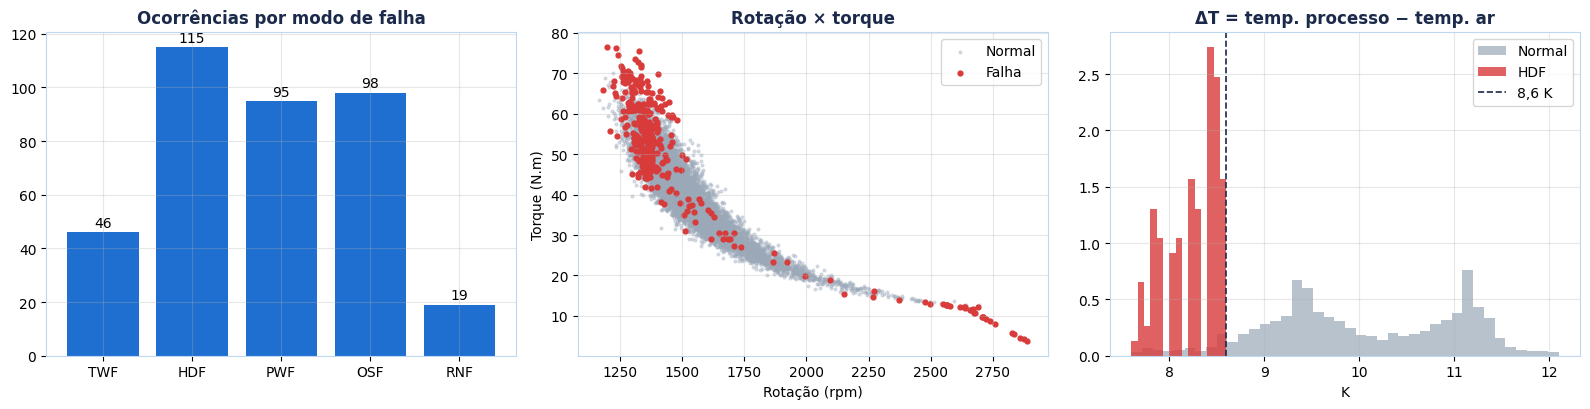

             mean     std     min      max
temp_ar     300.0     2.0   295.3    304.5
temp_proc   310.0     1.5   305.7    313.8
rotacao    1538.8   179.3  1168.0   2886.0
torque       40.0    10.0     3.8     76.6
desgaste    108.0    63.7     0.0    253.0
potencia   6279.7  1067.4  1148.4  10469.9


In [6]:
import matplotlib.pyplot as plt

AZUL, AZUL_ESCURO, VERMELHO, CINZA = "#1F6FD1", "#1B294A", "#D93A3A", "#9AA8B8"
plt.rcParams.update({"axes.edgecolor": "#BFD8F2", "axes.titleweight": "bold",
                     "axes.titlecolor": AZUL_ESCURO, "axes.grid": True, "grid.alpha": 0.3})

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.2))

contagem = {m: int(dados[m].sum()) for m in MODOS_FALHA}
eixos[0].bar(contagem.keys(), contagem.values(), color=AZUL)
eixos[0].set_title("Ocorrências por modo de falha")
for i, v in enumerate(contagem.values()):
    eixos[0].text(i, v + 2, str(v), ha="center", fontsize=10)

normais, falhas = dados[dados["falha"] == 0], dados[dados["falha"] == 1]
eixos[1].scatter(normais["rotacao"], normais["torque"], s=4, c=CINZA, alpha=0.35, label="Normal")
eixos[1].scatter(falhas["rotacao"], falhas["torque"], s=12, c=VERMELHO, label="Falha")
eixos[1].set_title("Rotação × torque")
eixos[1].set_xlabel("Rotação (rpm)"); eixos[1].set_ylabel("Torque (N.m)"); eixos[1].legend()

eixos[2].hist(normais["delta_t"], bins=40, color=CINZA, alpha=0.7, label="Normal", density=True)
eixos[2].hist(dados.loc[dados["HDF"] == 1, "delta_t"], bins=15, color=VERMELHO, alpha=0.8,
              label="HDF", density=True)
eixos[2].axvline(8.6, color=AZUL_ESCURO, ls="--", lw=1.2, label="8,6 K")
eixos[2].set_title("ΔT = temp. processo − temp. ar")
eixos[2].set_xlabel("K"); eixos[2].legend()

plt.tight_layout(); plt.show()

print(dados[["temp_ar", "temp_proc", "rotacao", "torque", "desgaste", "potencia"]]
      .describe().round(1).T[["mean", "std", "min", "max"]])

### Passo 4 — Treinando os modelos

Três modelos, cada um com um papel no sistema:

| Modelo | O que responde | Treinado com |
|---|---|---|
| Random Forest (falha) | Qual a probabilidade de este ciclo falhar? | Todos os ciclos de treino |
| Random Forest (modo) | Se falhar, qual o modo mais provável? | Só os ciclos com falha |
| Isolation Forest | Este ciclo é estranho em relação ao normal? (0 a 1) | Só os ciclos normais |

Como só 3,39% dos ciclos são falhas, o modelo de falha usa **pesos por classe**
(`class_weight`), senão ele aprenderia a responder "normal" sempre. Por isso
também avaliamos com precisão, recall e PR-AUC, e não com a acurácia.

Treino: 6000 ciclos (255 falhas)
Validação: 1000 ciclos (23 falhas)
Linha ao vivo: 3000 ciclos (61 falhas)

Relatório de classificação (linha ao vivo, limiar 0,5):
              precision    recall  f1-score   support

      Normal      0.994     0.999     0.996      2939
       Falha      0.917     0.721     0.807        61

    accuracy                          0.993      3000
   macro avg      0.955     0.860     0.902      3000
weighted avg      0.993     0.993     0.993      3000

PR-AUC: 0.797


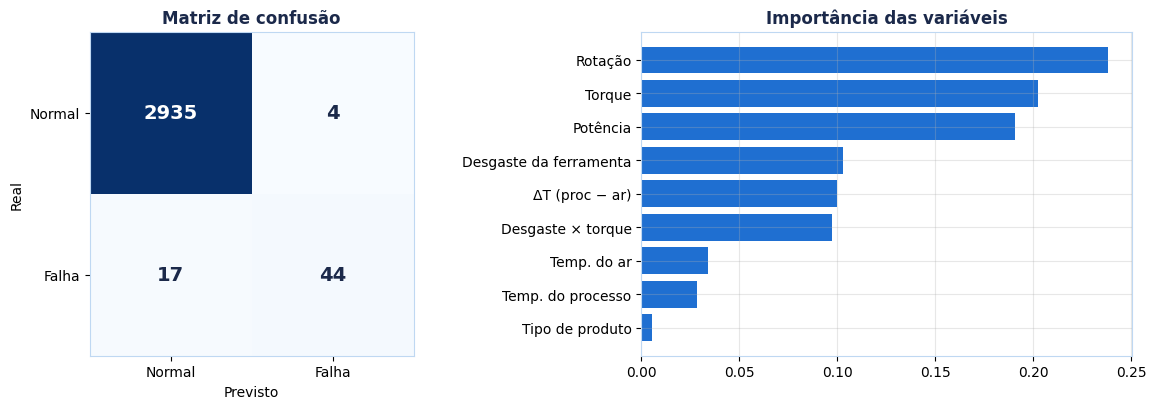

In [7]:
import warnings

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

# ---------------------------------------------------------------------------
# Divisão temporal: passado -> treino | validação | futuro -> linha ao vivo
# ---------------------------------------------------------------------------
fim_treino, fim_validacao = int(len(dados) * 0.60), int(len(dados) * 0.70)
treino = dados.iloc[:fim_treino]
validacao = dados.iloc[fim_treino:fim_validacao]
linha_ao_vivo = dados.iloc[fim_validacao:].reset_index(drop=True)

for nome, parte in [("Treino", treino), ("Validação", validacao), ("Linha ao vivo", linha_ao_vivo)]:
    print(f"{nome}: {len(parte)} ciclos ({int(parte['falha'].sum())} falhas)")

# ---- Modelo 1: probabilidade de falha ----
modelo_falha = RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                      class_weight="balanced_subsample", random_state=42, n_jobs=-1)
modelo_falha.fit(treino[FEATURES], treino["falha"])

# ---- Modelo 2: modo de falha (só ciclos com falha) ----
treino_falhas = treino[treino["falha"] == 1]
modelo_modo = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
modelo_modo.fit(treino_falhas[FEATURES], treino_falhas["modo"])

# ---- Modelo 3: detector de anomalias (só ciclos normais) ----
COLS_ANOMALIA = [f for f in FEATURES if f != "tipo_cod"]
treino_normal = treino[treino["falha"] == 0]
detector_anomalia = IsolationForest(n_estimators=200, random_state=42)
detector_anomalia.fit(treino_normal[COLS_ANOMALIA])

# referência para colocar o escore entre 0 (típico) e 1 (extremo)
_escores_normais = -detector_anomalia.score_samples(treino_normal[COLS_ANOMALIA])
ANOM_P50, ANOM_P995 = np.percentile(_escores_normais, [50, 99.5])


def escore_anomalia(df):
    """Escore de anomalia: 0 = típico da operação normal, 1 = extremo."""
    bruto = -detector_anomalia.score_samples(df[COLS_ANOMALIA])
    return np.clip((bruto - ANOM_P50) / (ANOM_P995 - ANOM_P50), 0, 1)


# ---------------------------------------------------------------------------
# Avaliação na linha ao vivo (dados que o modelo nunca viu), limiar padrão = 0,5
# ---------------------------------------------------------------------------
LIMIAR_PADRAO = 0.5
prob_teste = modelo_falha.predict_proba(linha_ao_vivo[FEATURES])[:, 1]
pred_teste = (prob_teste >= LIMIAR_PADRAO).astype(int)

print("\nRelatório de classificação (linha ao vivo, limiar 0,5):")
print(classification_report(linha_ao_vivo["falha"], pred_teste, target_names=["Normal", "Falha"], digits=3))
print(f"PR-AUC: {average_precision_score(linha_ao_vivo['falha'], prob_teste):.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

cm = confusion_matrix(linha_ao_vivo["falha"], pred_teste)
ax1.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax1.text(j, i, str(v), ha="center", va="center", fontsize=14, fontweight="bold",
             color="white" if v > cm.max() / 2 else AZUL_ESCURO)
ax1.set_xticks([0, 1], ["Normal", "Falha"]); ax1.set_yticks([0, 1], ["Normal", "Falha"])
ax1.set_xlabel("Previsto"); ax1.set_ylabel("Real"); ax1.set_title("Matriz de confusão"); ax1.grid(False)

importancia = pd.Series(modelo_falha.feature_importances_,
                        index=[NOMES_FEATURES[f] for f in FEATURES]).sort_values()
ax2.barh(importancia.index, importancia.values, color=AZUL)
ax2.set_title("Importância das variáveis")

plt.tight_layout(); plt.show()

#### Passo 5 — A linha ao vivo: ingestão amostra por amostra

A classe `LinhaProducao` simula a chegada dos dados dos sensores. A cada
chamada de `proxima()`, um novo ciclo entra no sistema e passa por quatro etapas:

    sensores  ->  3 modelos  ->  regras físicas  ->  alarme (sim/não)

É ela que alimenta o painel da aplicação final em tempo real.

A função `monitorar_linha` aplica o modelo a vários ciclos de uma vez e mostra,
num gráfico, quando o alarme teria disparado e quais falhas reais aconteceram.

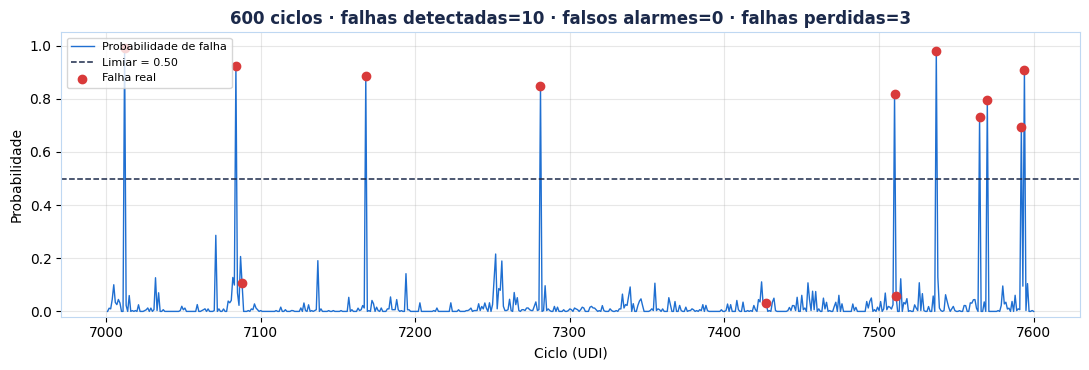

Precisão: 100.0%  (dos alarmes, quantos eram falha de verdade)
Recall:   76.9%  (das falhas reais, quantas o alarme pegou)

Teste de ingestão ao vivo (5 ciclos):
  20:07:54 ciclo 7001 | prob. falha = 0.000 | anomalia = 0.00 | alarme = False
  20:07:54 ciclo 7002 | prob. falha = 0.012 | anomalia = 0.00 | alarme = False
  20:07:54 ciclo 7003 | prob. falha = 0.010 | anomalia = 0.12 | alarme = False
  20:07:55 ciclo 7004 | prob. falha = 0.045 | anomalia = 0.26 | alarme = False
  20:07:55 ciclo 7005 | prob. falha = 0.100 | anomalia = 0.63 | alarme = False


In [8]:
import base64
import threading
from collections import deque
from datetime import datetime
from zoneinfo import ZoneInfo

# O Colab roda em UTC. O painel (Bloco 3) detecta o fuso do navegador de quem
# abre a tela e atualiza esta variável; aqui fica só o valor inicial.
FUSO_HORARIO = "America/Fortaleza"


def agora():
    """Horário local de quem está usando o painel."""
    try:
        return datetime.now(ZoneInfo(FUSO_HORARIO))
    except Exception:
        return datetime.now()


def verificar_regras(a):
    """Compara um ciclo com as regras físicas de cada modo de falha.
    Devolve uma lista de verificações com status OK, ATENÇÃO ou CRÍTICO."""
    lim_osf = LIMITE_OSF.get(a["tipo"], 11000)
    regras = []

    hdf_crit = a["delta_t"] < 8.6 and a["rotacao"] < 1380
    hdf_aten = a["delta_t"] < 9.5 and a["rotacao"] < 1450
    regras.append({"modo": "HDF", "condicao": "ΔT < 8,6 K e rotação < 1380 rpm",
                   "valor": f"ΔT={a['delta_t']:.2f} K · {a['rotacao']:.0f} rpm",
                   "status": "CRÍTICO" if hdf_crit else "ATENÇÃO" if hdf_aten else "OK"})

    p = a["potencia"]
    pwf_crit = p < 3500 or p > 9000
    pwf_aten = p < 3850 or p > 8200
    regras.append({"modo": "PWF", "condicao": "3500 W ≤ potência ≤ 9000 W",
                   "valor": f"{p:.0f} W",
                   "status": "CRÍTICO" if pwf_crit else "ATENÇÃO" if pwf_aten else "OK"})

    dt = a["desgaste_torque"]
    regras.append({"modo": "OSF", "condicao": f"desgaste × torque ≤ {lim_osf} min.N.m (tipo {a['tipo']})",
                   "valor": f"{dt:.0f} min.N.m",
                   "status": "CRÍTICO" if dt > lim_osf else "ATENÇÃO" if dt > 0.9 * lim_osf else "OK"})

    d = a["desgaste"]
    regras.append({"modo": "TWF", "condicao": "desgaste < 200 min (janela de troca 200–240 min)",
                   "valor": f"{d:.0f} min",
                   "status": "CRÍTICO" if d >= 240 else "ATENÇÃO" if d >= 200 else "OK"})
    return regras


def metricas_alarme(real, alarme):
    vp = int(((real == 1) & (alarme == 1)).sum())
    fp = int(((real == 0) & (alarme == 1)).sum())
    fn = int(((real == 1) & (alarme == 0)).sum())
    precisao = vp / (vp + fp) if (vp + fp) else 0.0
    recall = vp / (vp + fn) if (vp + fn) else 0.0
    f1 = 2 * precisao * recall / (precisao + recall) if (precisao + recall) else 0.0
    return vp, fp, fn, round(precisao * 100, 1), round(recall * 100, 1), round(f1 * 100, 1)


def figura_para_base64(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    buf.seek(0)
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode("utf-8")


# ---------------------------------------------------------------------------
# Linha de produção ao vivo
# ---------------------------------------------------------------------------
class LinhaProducao:
    def __init__(self, dados_linha, limiar=LIMIAR_PADRAO, janela=90):
        self.dados = dados_linha
        self.limiar = limiar
        self.janela = janela
        self.trava = threading.Lock()
        self.reiniciar()

    def reiniciar(self):
        with self.trava:
            self.posicao = 0
            self.historico = deque(maxlen=self.janela)
            self.alarmes = []
            self.contadores = {"amostras": 0, "alarmes": 0, "vp": 0, "fp": 0, "fn": 0, "falhas_reais": 0}
            self.ativa = True
            self.ultima = None

    def proxima(self):
        """Ingere o próximo ciclo: sensores -> modelos -> regras -> alarme."""
        with self.trava:
            if self.posicao >= len(self.dados):
                self.posicao = 0  # a linha recomeça do início (loop contínuo)
            bruto = self.dados.iloc[[self.posicao]]
            linha = bruto.iloc[0]
            prob = float(modelo_falha.predict_proba(bruto[FEATURES])[0, 1])
            alarme = prob >= self.limiar
            modo_prob = modelo_modo.predict_proba(bruto[FEATURES])[0]
            modo = str(modelo_modo.classes_[int(np.argmax(modo_prob))])
            amostra = {
                "hora": agora().strftime("%H:%M:%S"),
                "ciclo": int(linha["udi"]), "produto": linha["produto"], "tipo": linha["tipo"],
                "temp_ar": float(linha["temp_ar"]), "temp_proc": float(linha["temp_proc"]),
                "rotacao": float(linha["rotacao"]), "torque": float(linha["torque"]),
                "desgaste": float(linha["desgaste"]), "delta_t": float(linha["delta_t"]),
                "potencia": float(linha["potencia"]), "desgaste_torque": float(linha["desgaste_torque"]),
                "prob_falha": prob, "alarme": bool(alarme),
                "modo_previsto": modo if alarme else "-", "modo_conf": float(np.max(modo_prob)),
                "anomalia": float(escore_anomalia(bruto)[0]),
                "falha_real": int(linha["falha"]), "modo_real": linha["modo"],
            }
            amostra["regras"] = verificar_regras(amostra)

            c = self.contadores
            c["amostras"] += 1
            c["falhas_reais"] += amostra["falha_real"]
            if alarme:
                c["alarmes"] += 1
            if alarme and amostra["falha_real"]:
                c["vp"] += 1
                verificacao = "Falha confirmada"
            elif alarme:
                c["fp"] += 1
                verificacao = "Falso alarme"
            elif amostra["falha_real"]:
                c["fn"] += 1
                verificacao = "Falha não detectada"
            else:
                verificacao = None
            if verificacao:
                self.alarmes.insert(0, {**amostra, "verificacao": verificacao})
                self.alarmes = self.alarmes[:50]

            self.historico.append(amostra)
            self.ultima = amostra
            self.posicao += 1
            return amostra

    def avancar_ate_proxima_falha(self, antecedencia=6):
        """Pula a linha para alguns ciclos antes da próxima falha real (demonstração)."""
        with self.trava:
            futuras = np.where(self.dados["falha"].values[self.posicao + antecedencia:] == 1)[0]
            if len(futuras):
                self.posicao = int(self.posicao + futuras[0])

    def amostra_atual(self):
        if self.ultima is None:
            self.proxima()
        return self.ultima


LINHA = LinhaProducao(linha_ao_vivo)


def monitorar_linha(limiar=None, n_amostras=600):
    """Aplica o modelo a vários ciclos da linha ao vivo e mostra quando o alarme dispararia."""
    limiar = LINHA.limiar if limiar is None else float(limiar)
    janela = linha_ao_vivo.iloc[:n_amostras]
    prob = modelo_falha.predict_proba(janela[FEATURES])[:, 1]
    alarme = (prob >= limiar).astype(int)
    vp, fp, fn, precisao, recall, f1 = metricas_alarme(janela["falha"].values, alarme)

    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(janela["udi"], prob, color=AZUL, lw=1, label="Probabilidade de falha")
    ax.axhline(limiar, color=AZUL_ESCURO, ls="--", lw=1.1, label=f"Limiar = {limiar:.2f}")
    reais = janela["falha"].values == 1
    ax.scatter(janela["udi"][reais], prob[reais], color=VERMELHO, s=36, zorder=5, label="Falha real")
    ax.set_ylim(-0.02, 1.05); ax.set_xlabel("Ciclo (UDI)"); ax.set_ylabel("Probabilidade")
    ax.set_title(f"{len(janela)} ciclos · falhas detectadas={vp} · falsos alarmes={fp} · falhas perdidas={fn}")
    ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout(); plt.show()

    print(f"Precisão: {precisao}%  (dos alarmes, quantos eram falha de verdade)")
    print(f"Recall:   {recall}%  (das falhas reais, quantas o alarme pegou)")
    return {"vp": vp, "fp": fp, "fn": fn, "precisao": precisao, "recall": recall, "f1": f1}


resultados = monitorar_linha(n_amostras=600)

print("\nTeste de ingestão ao vivo (5 ciclos):")
for _ in range(5):
    a = LINHA.proxima()
    print(f"  {a['hora']} ciclo {a['ciclo']} | prob. falha = {a['prob_falha']:.3f} | "
          f"anomalia = {a['anomalia']:.2f} | alarme = {a['alarme']}")
LINHA.reiniciar()

#### Passo 6 — Escolha do limiar de alarme

O limiar de alarme é a probabilidade a partir da qual o sistema avisa o operador:

- **limiar baixo**: detecta mais falhas, mas gera mais falsos alarmes;
- **limiar alto**: menos falsos alarmes, mas mais falhas passam sem aviso.

Para escolher, testamos limiares de 0,05 a 0,95 no conjunto de **validação** e
ficamos com o de menor custo operacional:

    custo = 10 × (falhas não detectadas) + 1 × (falsos alarmes)

Uma falha não detectada custa 10 vezes mais porque significa uma parada não
planejada, enquanto um falso alarme custa só uma inspeção. O limiar escolhido
passa a valer na linha ao vivo e no painel.

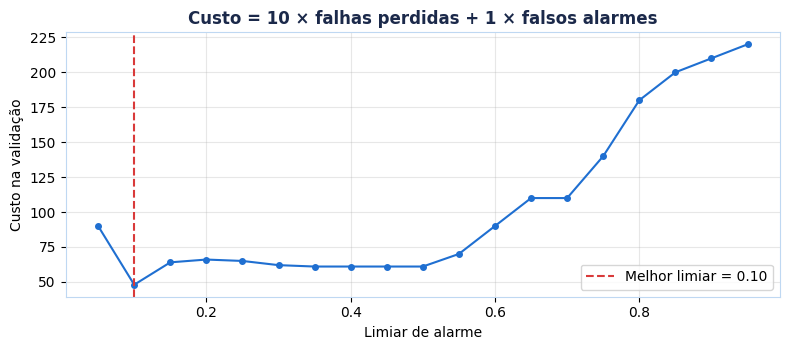

Limiar escolhido: 0.10 (custo 48 na validação)



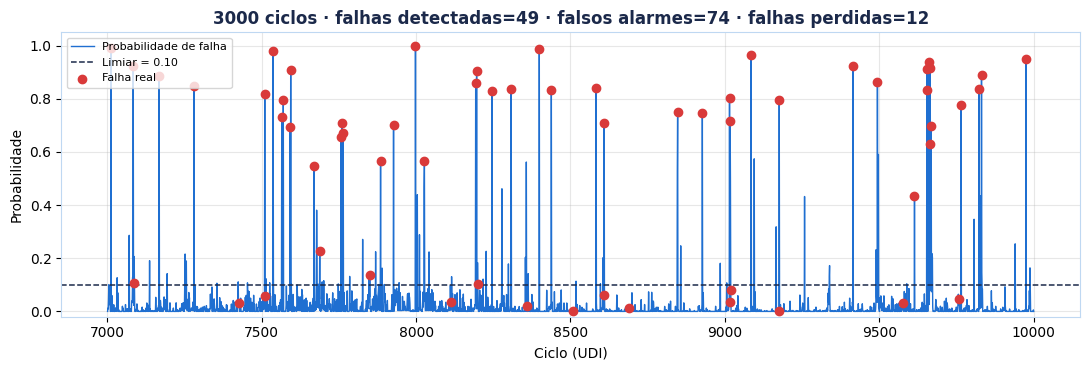

Precisão: 39.8%  (dos alarmes, quantos eram falha de verdade)
Recall:   80.3%  (das falhas reais, quantas o alarme pegou)


In [9]:
prob_validacao = modelo_falha.predict_proba(validacao[FEATURES])[:, 1]
real_validacao = validacao["falha"].values


def buscar_melhor_limiar(custo_fn=10, custo_fp=1):
    """Testa vários limiares na validação e aplica na linha o de menor custo."""
    linhas = []
    for limiar in np.arange(0.05, 0.96, 0.05):
        alarme = (prob_validacao >= limiar).astype(int)
        vp, fp, fn, precisao, recall, _ = metricas_alarme(real_validacao, alarme)
        linhas.append({"limiar": round(float(limiar), 2), "falhas detectadas": vp, "falsos alarmes": fp,
                       "falhas perdidas": fn, "custo": custo_fn * fn + custo_fp * fp})
    tabela = pd.DataFrame(linhas)
    melhor = tabela.loc[tabela["custo"].idxmin()]
    LINHA.limiar = float(melhor["limiar"])

    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(tabela["limiar"], tabela["custo"], "o-", color=AZUL, ms=4)
    ax.axvline(melhor["limiar"], color=VERMELHO, ls="--", label=f"Melhor limiar = {melhor['limiar']:.2f}")
    ax.set_xlabel("Limiar de alarme"); ax.set_ylabel("Custo na validação")
    ax.set_title(f"Custo = {custo_fn} × falhas perdidas + {custo_fp} × falsos alarmes"); ax.legend()
    plt.tight_layout(); plt.show()
    return melhor, tabela


melhor, tabela_limiares = buscar_melhor_limiar(custo_fn=10, custo_fp=1)
print(f"Limiar escolhido: {melhor['limiar']:.2f} (custo {melhor['custo']:.0f} na validação)\n")

# como o limiar escolhido se sai nos dados futuros (linha ao vivo inteira)
desempenho = monitorar_linha(limiar=LINHA.limiar, n_amostras=len(linha_ao_vivo))

#### Passo 7 — Diagnóstico de um ciclo com explicabilidade (XAI)

Quando o operador quer entender **por que** o sistema alarmou, a função
`diagnosticar_amostra` junta três visões de um ciclo:

1. **Modelo**: probabilidade de falha e modo mais provável.
2. **Regras físicas**: status de cada modo de falha (OK, ATENÇÃO ou CRÍTICO).
3. **SHAP**: quanto cada variável empurrou a previsão para cima (vermelho) ou
   para baixo (azul) naquele ciclo.

Esse gráfico também aparece no painel, ao lado da resposta da LLM. Se nenhum
valor for informado, o diagnóstico usa o ciclo mais recente da linha ao vivo.

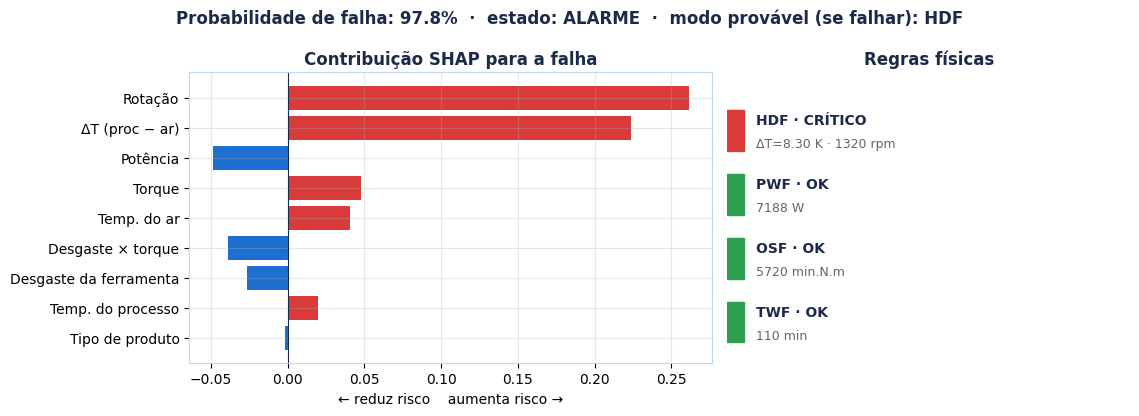

Estado: ALARME | probabilidade de falha: 97.8% | modo provável: HDF
  HDF: CRÍTICO  (ΔT=8.30 K · 1320 rpm)
  PWF: OK       (7188 W)
  OSF: OK       (5720 min.N.m)
  TWF: OK       (110 min)


In [10]:
!pip install -q shap

import shap

explicador_shap = shap.TreeExplainer(modelo_falha)


def contribuicoes_shap(x):
    """Contribuição de cada variável para a probabilidade de falha de um ciclo."""
    valores = explicador_shap.shap_values(x[FEATURES])
    valores = valores[1] if isinstance(valores, list) else np.asarray(valores)
    if valores.ndim == 3:  # versões novas do SHAP: (ciclos, variáveis, classes)
        valores = valores[:, :, 1]
    return pd.Series(valores[0], index=[NOMES_FEATURES[f] for f in FEATURES])


def diagnosticar_amostra(valores=None, mostrar=True):
    """Diagnóstico de um ciclo: modelo + regras físicas + SHAP. Devolve o gráfico pronto para o painel."""
    base = dict(LINHA.amostra_atual())
    if valores:
        base.update(valores)
    x = adicionar_features(pd.DataFrame([{k: base[k] for k in
                                          ["tipo", "temp_ar", "temp_proc", "rotacao", "torque", "desgaste"]}]))

    prob = float(modelo_falha.predict_proba(x[FEATURES])[0, 1])
    modo = str(modelo_modo.predict(x[FEATURES])[0])
    regras = verificar_regras(x.iloc[0].to_dict())
    contrib = contribuicoes_shap(x).sort_values(key=abs)
    estado = "ALARME" if prob >= LINHA.limiar else "ATENÇÃO" if (
        prob >= LINHA.limiar / 2 or any(r["status"] != "OK" for r in regras)) else "NORMAL"

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
    fig.suptitle(f"Probabilidade de falha: {prob * 100:.1f}%  ·  estado: {estado}  ·  modo provável (se falhar): {modo}",
                 color=AZUL_ESCURO, fontweight="bold", fontsize=12)
    ax1.barh(contrib.index, contrib.values, color=[VERMELHO if v > 0 else AZUL for v in contrib.values])
    ax1.axvline(0, color=AZUL_ESCURO, lw=0.8)
    ax1.set_title("Contribuição SHAP para a falha"); ax1.set_xlabel("← reduz risco    aumenta risco →")

    cores_status = {"OK": "#2E9E4F", "ATENÇÃO": "#F4B400", "CRÍTICO": VERMELHO}
    ax2.axis("off"); ax2.set_title("Regras físicas", color=AZUL_ESCURO, fontweight="bold")
    for i, r in enumerate(regras):
        y = 0.8 - i * 0.22
        ax2.add_patch(plt.Rectangle((0, y - 0.07), 0.04, 0.14, color=cores_status[r["status"]]))
        ax2.text(0.07, y + 0.02, f"{r['modo']} · {r['status']}", fontsize=10, fontweight="bold", color=AZUL_ESCURO)
        ax2.text(0.07, y - 0.06, r["valor"], fontsize=9, color="#5B6577")
    plt.tight_layout()
    if mostrar:
        plt.show()

    return {"estado": estado, "prob_falha": round(prob * 100, 1), "modo_provavel": modo,
            "regras": regras, "contribuicoes": contrib.round(3).to_dict(), "grafico": figura_para_base64(fig)}


# ---------------------------------------------------------------------------
# Teste: um ciclo com risco de dissipação de calor (HDF)
# ---------------------------------------------------------------------------
diag = diagnosticar_amostra({"tipo": "L", "temp_ar": 302.5, "temp_proc": 310.8,
                             "rotacao": 1320, "torque": 52.0, "desgaste": 110})
print(f"Estado: {diag['estado']} | probabilidade de falha: {diag['prob_falha']}% | "
      f"modo provável: {diag['modo_provavel']}")
for r in diag["regras"]:
    print(f"  {r['modo']}: {r['status']:8} ({r['valor']})")

### Construção dos prompts de instrução

Agora conectamos os dados da planta à LLM. A pergunta do operador é sempre
a mesma ("qual o estado da máquina neste ciclo?"), mas o **prompt** muda, e
com ele muda a qualidade da resposta. Vamos comparar quatro técnicas:

| Técnica | O que o prompt contém |
|---|---|
| Zero-shot | Só a instrução e os dados do ciclo, sem exemplos nem regras |
| Few-shot | Instrução + exemplos reais de ciclos já diagnosticados (entrada → saída) |
| Chain-of-thought | Instrução + regras de falha + pedido de raciocínio passo a passo |
| Estruturado (PROMPT) | Persona, Roteiro, Objetivo, Modelo de saída (JSON), Panorama (ficha técnica) e Transformar, separados por delimitadores |

#### Verificação da resposta

Uma LLM pode errar contas ou inventar limites com toda a confiança
(alucinação). Por isso, toda resposta passa por uma **verificação
automática**, que compara o que a LLM disse com três referências:

1. O **estado calculado pelo sistema** (modelo de ML + regras físicas).
2. Os **cálculos de engenharia** (ΔT, potência e desgaste × torque), quando a
   LLM os informa.
3. O **rótulo real** do dataset AI4I.

In [11]:
import html
import json
import re

from langchain_core.messages import HumanMessage, SystemMessage


def estado_sistema(a, limiar=None):
    """Estado de referência: modelo de ML + regras físicas."""
    limiar = LINHA.limiar if limiar is None else limiar
    if a["prob_falha"] >= limiar or any(r["status"] == "CRÍTICO" for r in a["regras"]):
        return "ALARME"
    if a["prob_falha"] >= limiar / 2 or any(r["status"] == "ATENÇÃO" for r in a["regras"]):
        return "ATENÇÃO"
    return "NORMAL"


def montar_amostra(linha):
    """Converte uma linha do dataset no mesmo formato de amostra da linha ao vivo."""
    df1 = pd.DataFrame([linha])
    prob = float(modelo_falha.predict_proba(df1[FEATURES])[0, 1])
    a = {
        "ciclo": int(linha["udi"]), "produto": linha["produto"], "tipo": linha["tipo"],
        **{k: float(linha[k]) for k in ["temp_ar", "temp_proc", "rotacao", "torque", "desgaste",
                                         "delta_t", "potencia", "desgaste_torque"]},
        "prob_falha": prob, "alarme": prob >= LINHA.limiar,
        "anomalia": float(escore_anomalia(df1)[0]),
        "falha_real": int(linha["falha"]), "modo_real": linha["modo"],
    }
    a["regras"] = verificar_regras(a)
    return a


# ---------------------------------------------------------------------------
# Blocos de texto reutilizados nos prompts
# ---------------------------------------------------------------------------
def dados_ciclo_texto(a, incluir_modelo=True):
    txt = (
        f"Ciclo (UDI): {a['ciclo']} | Produto: {a['tipo']} ({a['produto']})\n"
        f"Temperatura do ar: {a['temp_ar']:.1f} K\n"
        f"Temperatura do processo: {a['temp_proc']:.1f} K\n"
        f"Rotação: {a['rotacao']:.0f} rpm\n"
        f"Torque: {a['torque']:.1f} N.m\n"
        f"Desgaste da ferramenta: {a['desgaste']:.0f} min"
    )
    if incluir_modelo:
        txt += (f"\nSaída do modelo de ML: probabilidade de falha = {a['prob_falha'] * 100:.1f}% "
                f"(limiar de alarme {LINHA.limiar * 100:.0f}%); escore de anomalia = {a['anomalia']:.2f} "
                f"(0 = típico, 1 = extremo)")
    return txt


REGRAS_TEXTO = """- HDF (dissipação de calor): ΔT = temp. processo − temp. ar < 8,6 K E rotação < 1380 rpm
- PWF (potência): potência = torque × rotação × 2π / 60 fora da faixa 3500 W a 9000 W
- OSF (sobrecarga): desgaste × torque > 11000 (produto L), 12000 (M) ou 13000 (H) min.N.m
- TWF (desgaste da ferramenta): troca ou falha entre 200 e 240 min de desgaste
- Atenção: valores a menos de 10% de um limite"""

FORMATO_JSON = """{
  "estado": "NORMAL" | "ATENÇÃO" | "ALARME",
  "modo_provavel": "HDF" | "PWF" | "OSF" | "TWF" | "NENHUM",
  "calculos": {"delta_t_K": número, "potencia_W": número, "desgaste_torque": número},
  "justificativa": "texto curto citando os valores e limites",
  "acao_recomendada": "texto curto"
}"""


INSTRUCOES_RELATORIO = """Escreva primeiro um relatório para o operador, em texto corrido, com 3 parágrafos:
1) O que está acontecendo: cite os valores do ciclo e os cálculos de ΔT, potência e desgaste × torque,
   comparando cada um com o seu limite.
2) O que isso significa: o risco para a máquina, qual modo de falha está mais próximo e por quê,
   e o que a saída do modelo de ML indica.
3) O que fazer: a ação recomendada e o que acompanhar nos próximos ciclos.
Escreva de forma clara para um operador de chão de fábrica. Não use tabelas nem LaTeX."""


def justificativa_por_regras(a):
    criticos = [r for r in a["regras"] if r["status"] == "CRÍTICO"]
    if not criticos:
        return (f"ΔT={a['delta_t']:.1f} K, potência={a['potencia']:.0f} W e desgaste×torque="
                f"{a['desgaste_torque']:.0f} min.N.m dentro dos limites")
    return "; ".join(f"{r['modo']}: {r['valor']} viola '{r['condicao']}'" for r in criticos)


ACOES = {
    "HDF": "verificar refrigeração e ventilação e avaliar aumento da rotação",
    "PWF": "revisar parâmetros de corte e inspecionar motor e acionamento",
    "OSF": "reduzir o torque e programar a troca da ferramenta",
    "TWF": "planejar a troca da ferramenta no próximo setup",
    "NENHUM": "nenhuma ação necessária",
}


def exemplos_few_shot():
    """Seleciona exemplos reais do conjunto de TREINO: um normal e um de cada modo."""
    exemplos = [treino[treino["falha"] == 0].iloc[100]]
    for modo in ["HDF", "PWF", "OSF"]:
        so_este = treino[(treino[modo] == 1) & (treino[MODOS_FALHA].sum(axis=1) == 1)]
        if modo == "HDF":
            so_este = so_este.sort_values("delta_t")  # exemplo inequívoco, longe do limite de 8,6 K
        exemplos.append(so_este.iloc[0])
    blocos = []
    for linha in exemplos:
        a = montar_amostra(linha)
        modo = a["modo_real"] if a["falha_real"] else "NENHUM"
        estado = "ALARME" if a["falha_real"] else "NORMAL"
        blocos.append(
            f"Entrada:\n{dados_ciclo_texto(a, incluir_modelo=False)}\n"
            f"Saída: Estado: {estado} | Modo: {modo} | Justificativa: {justificativa_por_regras(a)} | "
            f"Ação: {ACOES[modo]}"
        )
    return "\n\n".join(blocos)


EXEMPLOS_FEW_SHOT = exemplos_few_shot()


# ---------------------------------------------------------------------------
# As quatro técnicas de prompt
# ---------------------------------------------------------------------------
def prompt_zero_shot(pergunta, a, incluir_modelo):
    return [HumanMessage(
        f"{pergunta}\n\n{dados_ciclo_texto(a, incluir_modelo)}\n\n"
        "Termine com uma linha no formato: Estado: NORMAL/ATENÇÃO/ALARME | Modo: HDF/PWF/OSF/TWF/NENHUM"
    )]


def prompt_few_shot(pergunta, a, incluir_modelo):
    return [
        SystemMessage("Você classifica ciclos de uma fresadora industrial. Siga exatamente o padrão dos exemplos."),
        HumanMessage(
            f"Exemplos de ciclos já diagnosticados pela engenharia:\n\n{EXEMPLOS_FEW_SHOT}\n\n"
            f"Agora o novo ciclo. Pergunta do operador: {pergunta}\n\n"
            f"Entrada:\n{dados_ciclo_texto(a, incluir_modelo)}\nSaída:"
        ),
    ]


def prompt_chain_of_thought(pergunta, a, incluir_modelo):
    return [
        SystemMessage("Você é um engenheiro de manutenção preditiva. Responda em português."),
        HumanMessage(
            f"{pergunta}\n\nDados do ciclo:\n{dados_ciclo_texto(a, incluir_modelo)}\n\n"
            f"Regras de falha da máquina:\n{REGRAS_TEXTO}\n\n"
            "Pense passo a passo antes de concluir:\n"
            "1) Calcule ΔT e compare com 8,6 K, junto com a rotação e 1380 rpm.\n"
            "2) Calcule a potência em W e compare com a faixa 3500–9000 W.\n"
            "3) Calcule desgaste × torque e compare com o limite do tipo de produto.\n"
            "4) Compare o desgaste com a janela de 200–240 min.\n"
            "5) Considere a saída do modelo de ML, se houver, e conclua.\n\n"
            f"Ao final, escreva a conclusão SOMENTE neste JSON:\n{FORMATO_JSON}"
        ),
    ]


def prompt_estruturado(pergunta, a, incluir_modelo):
    sistema = f"""### PERSONA ###
Você é engenheiro de confiabilidade sênior, responsável pela fresadora FR-01.

### PANORAMA ###
{ficha_maquina.strip()}

### ROTEIRO ###
1. Calcule ΔT, potência (W) e desgaste × torque a partir dos dados do ciclo.
2. Compare cada valor com as regras abaixo e marque ATENÇÃO a menos de 10% de um limite.
3. Use a saída do modelo de ML como evidência complementar, se houver.
4. Se não houver informação suficiente, diga isso na justificativa; não invente valores.

### REGRAS ###
{REGRAS_TEXTO}

### OBJETIVO ###
Dar ao operador um diagnóstico detalhado do ciclo e uma ação objetiva.

### MODELO DE SAÍDA ###
{INSTRUCOES_RELATORIO}

Depois do relatório, termine a resposta com este JSON (ele é lido pelo sistema de verificação):
{FORMATO_JSON}

### TRANSFORMAR ###
Use linguagem técnica e clara, em português, com números arredondados a 1 casa decimal."""
    return [
        SystemMessage(sistema),
        HumanMessage(f"### PERGUNTA ###\n{pergunta}\n\n### DADOS DO CICLO ###\n{dados_ciclo_texto(a, incluir_modelo)}"),
    ]


TECNICAS = {
    "Zero-shot": prompt_zero_shot,
    "Few-shot": prompt_few_shot,
    "Chain-of-thought": prompt_chain_of_thought,
    "Estruturado (PROMPT)": prompt_estruturado,
}


def prompt_como_texto(mensagens):
    partes = []
    for m in mensagens:
        papel = "SISTEMA" if isinstance(m, SystemMessage) else "USUÁRIO"
        partes.append(f"[{papel}]\n{m.content}")
    return "\n\n".join(partes)


# ---------------------------------------------------------------------------
# Verificação automática da resposta
# ---------------------------------------------------------------------------
def extrair_resposta(texto):
    saida = {}
    blocos_json = re.findall(r"\{(?:[^{}]|\{[^{}]*\})*\}", texto or "")
    saida["json"], saida["texto_livre"] = {}, (texto or "").strip()
    for bloco in reversed(blocos_json):
        try:
            j = json.loads(bloco)
            saida["estado"] = str(j.get("estado", "")).upper() or None
            saida["modo"] = str(j.get("modo_provavel", "")).upper() or None
            saida["calculos"] = j.get("calculos") or {}
            saida["json"] = j
            livre = (texto or "").replace(bloco, "")
            saida["texto_livre"] = re.sub(r"```(json)?\s*```", "", livre).strip()
            break
        except Exception:
            continue
    if not saida.get("estado"):
        m = re.findall(r"estado\W{0,4}\s*[:=]\s*\**\s*(NORMAL|ATEN[ÇC][ÃA]O|ALARME)", texto or "", re.I)
        saida["estado"] = m[-1].upper().replace("ATENCAO", "ATENÇÃO") if m else None
    if not saida.get("modo"):
        m = re.findall(r"modo[^:\n]{0,20}[:=]\s*\**\s*(HDF|PWF|OSF|TWF|RNF|NENHUM)", texto or "", re.I)
        saida["modo"] = m[-1].upper() if m else None
    return saida


def verificar_resposta(texto, a):
    r = extrair_resposta(texto)
    criticos = [x["modo"] for x in a["regras"] if x["status"] == "CRÍTICO"]
    modo_regras = criticos[0] if criticos else "NENHUM"
    modo_real = a["modo_real"] if a["falha_real"] else "NENHUM"
    checks = []

    def add(item, valor_llm, referencia, ok):
        checks.append({"item": item, "llm": valor_llm if valor_llm is not None else "—",
                       "referencia": referencia, "ok": ok})

    add("Estado", r.get("estado"), estado_sistema(a), r.get("estado") == estado_sistema(a))
    add("Modo × regras físicas", r.get("modo"), " / ".join(criticos) or "NENHUM",
        r.get("modo") in (criticos or ["NENHUM"]))
    add("Modo × rótulo real (AI4I)", r.get("modo"), modo_real,
        r.get("modo") == modo_real or (modo_real == "NENHUM" and r.get("modo") in (None, "NENHUM")))

    calc = r.get("calculos") or {}
    referencias = {"delta_t_K": ("ΔT (K)", a["delta_t"]), "potencia_W": ("Potência (W)", a["potencia"]),
                   "desgaste_torque": ("Desgaste × torque", a["desgaste_torque"])}
    for chave, (nome, ref) in referencias.items():
        if chave in calc:
            try:
                v = float(calc[chave])
                add(f"Cálculo {nome}", round(v, 1), round(ref, 1), abs(v - ref) <= max(0.02 * abs(ref), 0.15))
            except (TypeError, ValueError):
                add(f"Cálculo {nome}", calc[chave], round(ref, 1), False)
    return checks


def perguntar_llm(pergunta, tecnica="Estruturado (PROMPT)", amostra=None, temperatura=0.1, incluir_modelo=True):
    a = amostra or LINHA.amostra_atual()
    mensagens = TECNICAS[tecnica](pergunta, a, incluir_modelo)
    try:
        modelo = llm.model_copy(update={"temperature": float(temperatura)})
    except Exception:
        modelo = llm
    resposta = modelo.invoke(mensagens).content
    return {
        "tecnica": tecnica, "prompt": prompt_como_texto(mensagens), "resposta": resposta,
        "verificacao": verificar_resposta(resposta, a), "amostra": a,
        "tokens_aprox": len(prompt_como_texto(mensagens)) // 4,
    }


print("Exemplos few-shot selecionados do conjunto de treino:\n")
print(EXEMPLOS_FEW_SHOT)

Exemplos few-shot selecionados do conjunto de treino:

Entrada:
Ciclo (UDI): 104 | Produto: M (M14963)
Temperatura do ar: 298.8 K
Temperatura do processo: 308.8 K
Rotação: 1441 rpm
Torque: 40.5 N.m
Desgaste da ferramenta: 63 min
Saída: Estado: NORMAL | Modo: NENHUM | Justificativa: ΔT=10.0 K, potência=6111 W e desgaste×torque=2552 min.N.m dentro dos limites | Ação: nenhuma ação necessária

Entrada:
Ciclo (UDI): 4422 | Produto: L (L51601)
Temperatura do ar: 302.6 K
Temperatura do processo: 310.2 K
Rotação: 1325 rpm
Torque: 62.4 N.m
Desgaste da ferramenta: 92 min
Saída: Estado: ALARME | Modo: HDF | Justificativa: HDF: ΔT=7.60 K · 1325 rpm viola 'ΔT < 8,6 K e rotação < 1380 rpm' | Ação: verificar refrigeração e ventilação e avaliar aumento da rotação

Entrada:
Ciclo (UDI): 51 | Produto: L (L47230)
Temperatura do ar: 298.9 K
Temperatura do processo: 309.1 K
Rotação: 2861 rpm
Torque: 4.6 N.m
Desgaste da ferramenta: 143 min
Saída: Estado: ALARME | Modo: PWF | Justificativa: PWF: 1378 W viola

### Comparando as quatro técnicas no mesmo ciclo

Escolhemos da linha ao vivo um ciclo com falha real (HDF, PWF ou OSF) e
fazemos a mesma pergunta com as quatro técnicas. Observe:

- o tamanho do prompt (tokens aproximados) cresce da técnica zero-shot até a
  estruturada;
- quais técnicas acertam o estado e o modo de falha;
- se os cálculos informados pela LLM conferem com os valores reais.

Experimente também mudar a temperatura ou retirar a saída do modelo de ML
(incluir_modelo=False) para ver como a LLM se comporta só com os sensores.

In [12]:
# primeiro ciclo da linha ao vivo com falha real de um único modo (HDF, PWF ou OSF)
candidatos = linha_ao_vivo[(linha_ao_vivo["falha"] == 1) & (linha_ao_vivo["modo"].isin(["HDF", "PWF", "OSF"]))
                           & (linha_ao_vivo[MODOS_FALHA].sum(axis=1) == 1)]
ciclo_teste = candidatos.iloc[0]
amostra_teste = montar_amostra(ciclo_teste)
pergunta_teste = "Qual o estado da máquina neste ciclo e qual ação você recomenda?"

print(f"Ciclo escolhido: UDI {amostra_teste['ciclo']} | estado do sistema: {estado_sistema(amostra_teste)} "
      f"| rótulo real: {amostra_teste['modo_real']}\n")

comparacao = []
for tecnica in TECNICAS:
    r = perguntar_llm(pergunta_teste, tecnica, amostra=amostra_teste, temperatura=0.1, incluir_modelo=True)
    acertos = sum(c["ok"] for c in r["verificacao"])
    comparacao.append({"técnica": tecnica, "tokens do prompt (aprox.)": r["tokens_aprox"],
                       "acertos": f"{acertos}/{len(r['verificacao'])}"})
    print("=" * 80)
    print(f"TÉCNICA: {tecnica}  (~{r['tokens_aprox']} tokens de prompt)")
    print("=" * 80)
    print(r["resposta"][:4000])
    print("\nVerificação:")
    for c in r["verificacao"]:
        print(f"  {'✅' if c['ok'] else '❌'} {c['item']:<28} LLM: {str(c['llm']):<10} referência: {c['referencia']}")
    print()

display(pd.DataFrame(comparacao))

# Para ver o prompt completo de uma técnica:
# print(perguntar_llm(pergunta_teste, "Estruturado (PROMPT)", amostra=amostra_teste)["prompt"])

Ciclo escolhido: UDI 7012 | estado do sistema: ALARME | rótulo real: PWF

TÉCNICA: Zero-shot  (~116 tokens de prompt)
**Estado da máquina:** ALARME  
**Ação recomendada:**  
- Interromper imediatamente a operação para evitar falha catastrófica.  
- Verificar a condição da ferramenta (desgaste de 17 min indica desgaste crítico).  
- Revisar e ajustar a temperatura do ar e do processo (300.5 K / 310.5 K) para garantir que estejam dentro das faixas de operação seguras.  
- Analisar a rotação (2633 rpm) e torque (12.2 N·m) em relação às especificações do produto L (L54191) e ajustar se necessário.  
- Realizar manutenção preventiva ou substituição da ferramenta antes de retomar a produção.  
- Registrar o evento e atualizar o histórico de falhas para melhorar o modelo de ML.

Estado: ALARME | Modo: NENHUM

Verificação:
  ✅ Estado                       LLM: ALARME     referência: ALARME
  ❌ Modo × regras físicas        LLM: NENHUM     referência: PWF
  ❌ Modo × rótulo real (AI4I)    LLM: NE

,técnica,tokens do prompt (aprox.),acertos
0,Zero-shot,116,1/3
1,Few-shot,497,3/3
2,Chain-of-thought,396,6/6
3,Estruturado (PROMPT),906,6/6


### Aplicação final — Interface

Engenharia de prompt + interação com o usuário, em um único painel.

Painel de monitoramento no estilo de um sistema supervisório (SCADA), com
ingestão automática de dados: a cada intervalo, um novo ciclo da linha ao
vivo chega dos "sensores", passa pelos modelos e atualiza o painel.

- **Faixa superior**: estado da máquina, probabilidade de falha, modo
  provável, anomalia, produto em processo e desempenho do sistema de alarme.
- **Sinótico**: a fresadora com os transmissores (tags) e o sinaleiro; cada
  tag muda de cor conforme as regras físicas.
- **Tendências**: as últimas 90 amostras de cada variável, com os limites.
- **Registro de eventos**: alarmes confirmados, falsos alarmes e falhas não
  detectadas, comparados com o rótulo real do dataset.
- **Controle da linha**: pausar, avançar até a próxima falha (para
  demonstração), reiniciar, intervalo de ingestão e limiar de alarme.
- **Console da LLM**: o operador escolhe a técnica de prompt e pergunta sobre o
  ciclo atual. Com a opção de RAG marcada, os trechos relevantes dos PDFs da
  planta entram no prompt e as fontes aparecem na resposta. A resposta vem como
  um relatório em texto (o que está acontecendo, o que significa e o que fazer),
  acompanhada da verificação automática contra o sistema e o rótulo real e do
  diagnóstico SHAP do ciclo.

Como a linha é única, todos que abrirem o link veem a mesma planta.

In [13]:
!pip install -q gradio

import time
from datetime import datetime

import gradio as gr
from PIL import Image

GR_MAJOR = int(gr.__version__.split(".")[0])

# ---------------------------------------------------------------------------
# Paleta — branco e azul-marinho, no padrão do template da aula
# ---------------------------------------------------------------------------
MARINHO, AZ, AZ_VIVO, AZ_CLARO = "#1B294A", "#025699", "#1F6FD1", "#4FA3E0"
FUNDO, BORDA, PALIDO = "#EEF3F9", "#D6E2F0", "#EAF3FC"
VERDE, AMBAR, VERM, CINZA_TXT = "#2E9E4F", "#E8A300", "#D93A3A", "#5B6577"

TEMA_INDUSTRIAL = gr.themes.Base(
    primary_hue=gr.themes.colors.blue,
    secondary_hue=gr.themes.colors.slate,
    neutral_hue=gr.themes.colors.slate,
    font=[gr.themes.GoogleFont("Open Sans"), "Arial", "sans-serif"],
    font_mono=[gr.themes.GoogleFont("Roboto Mono"), "ui-monospace", "monospace"],
    text_size=gr.themes.sizes.text_md,
).set(
    body_background_fill=FUNDO,
    body_background_fill_dark=FUNDO,
    background_fill_primary="#FFFFFF",
    background_fill_primary_dark="#FFFFFF",
    background_fill_secondary="#F6F9FC",
    background_fill_secondary_dark="#F6F9FC",
    border_color_primary=BORDA,
    border_color_primary_dark=BORDA,
    block_background_fill="#FFFFFF",
    block_background_fill_dark="#FFFFFF",
    block_border_color=BORDA,
    block_border_color_dark=BORDA,
    block_label_background_fill=PALIDO,
    block_label_background_fill_dark=PALIDO,
    block_label_text_color=AZ,
    block_label_text_color_dark=AZ,
    block_title_text_color=MARINHO,
    block_title_text_color_dark=MARINHO,
    body_text_color=MARINHO,
    body_text_color_dark=MARINHO,
    body_text_color_subdued=CINZA_TXT,
    body_text_color_subdued_dark=CINZA_TXT,
    button_primary_background_fill=AZ,
    button_primary_background_fill_hover=AZ_VIVO,
    button_primary_text_color="#FFFFFF",
    button_primary_border_color=AZ,
    button_secondary_background_fill="#FFFFFF",
    button_secondary_background_fill_hover=PALIDO,
    button_secondary_text_color=AZ,
    button_secondary_border_color=AZ,
    input_background_fill="#FFFFFF",
    input_background_fill_dark="#FFFFFF",
    input_border_color=BORDA,
    input_border_color_dark=BORDA,
    input_border_color_focus=AZ_VIVO,
    input_border_color_focus_dark=AZ_VIVO,
    input_placeholder_color="#8A96A8",
    input_placeholder_color_dark="#8A96A8",
    shadow_drop="0 1px 3px rgba(27,41,74,0.08)",
)

CSS_INDUSTRIAL = """
@import url('https://fonts.googleapis.com/css2?family=Fira+Sans:wght@500;600;700&family=Roboto+Mono:wght@500;700&display=swap');
.gradio-container { background: #EEF3F9 !important; max-width: 1500px !important; }
footer { display: none !important; }

/* ---------- cabeçalho ---------- */
.pdm-header { display:flex; justify-content:space-between; align-items:center;
  background: linear-gradient(90deg, #1B294A 0%, #025699 100%); color:#fff;
  border-radius:12px; padding:14px 22px; box-shadow:0 4px 14px rgba(2,86,153,0.25); }
.pdm-header-l { display:flex; align-items:center; gap:14px; }
.pdm-logo { width:46px; height:46px; border-radius:10px; background:#fff; color:#025699;
  display:flex; align-items:center; justify-content:center; font:700 15px 'Fira Sans',sans-serif; }
.pdm-titulo { font:700 19px 'Fira Sans',sans-serif; letter-spacing:1.2px; color:#FFFFFF !important; }
.pdm-sub { font-size:12.5px; opacity:0.85; margin-top:2px; color:#FFFFFF !important; }
.pdm-header-r, .pdm-header-r span { color:#FFFFFF !important; }
.pdm-header-r { display:flex; align-items:center; gap:18px; font-family:'Roboto Mono',monospace; font-size:13px; }
.pdm-live { display:flex; align-items:center; gap:8px; background:rgba(255,255,255,0.12);
  border:1px solid rgba(255,255,255,0.35); border-radius:20px; padding:5px 12px; font-weight:700; letter-spacing:1px; }
.pdm-dot { width:10px; height:10px; border-radius:50%; background:#4ADE80; box-shadow:0 0 8px #4ADE80;
  animation: pdmpulso 1s ease-in-out infinite; }
.pdm-dot.pausa { background:#F4B400; box-shadow:0 0 6px #F4B400; animation:none; }
.pdm-hora { display:flex; flex-direction:column; align-items:flex-end; line-height:1.1; }
.pdm-relogio { font-size:22px; font-weight:700; }
.pdm-data { font-size:10.5px; opacity:0.8; }
@keyframes pdmpulso { 0%,100% { opacity:1; } 50% { opacity:0.25; } }

/* ---------- KPIs ---------- */
.pdm-kpis { display:grid; grid-template-columns: repeat(7, 1fr); gap:10px; margin-top:12px; }
.pdm-kpi { background:#fff; border:1px solid #D6E2F0; border-top:4px solid #025699; border-radius:10px;
  padding:10px 12px; box-shadow:0 1px 3px rgba(27,41,74,0.06); min-height:92px; }
.pdm-kpi-l { font-size:10.5px; font-weight:700; letter-spacing:0.8px; color:#5B6577; text-transform:uppercase; }
.pdm-kpi-v { font:700 24px 'Fira Sans',sans-serif; color:#1B294A; margin-top:4px; line-height:1.15; }
.pdm-kpi-s { font-size:11.5px; color:#5B6577; margin-top:3px; }
.pdm-chip { display:inline-block; padding:5px 12px; border-radius:6px; color:#fff;
  font:700 17px 'Fira Sans',sans-serif; letter-spacing:1px; margin-top:4px; }
.pdm-barra { height:7px; background:#EAF3FC; border-radius:4px; margin-top:7px; position:relative; overflow:visible; }
.pdm-barra > span { display:block; height:7px; border-radius:4px; }
.pdm-marca { position:absolute; top:-3px; width:2px; height:13px; background:#1B294A; }

/* ---------- cartões ---------- */
.pdm-card { background:#fff; border:1px solid #D6E2F0; border-radius:12px; padding:12px 14px;
  box-shadow:0 1px 3px rgba(27,41,74,0.06); }
.pdm-card-h { display:flex; justify-content:space-between; align-items:center; font:700 12.5px 'Fira Sans',sans-serif;
  letter-spacing:1px; color:#025699; text-transform:uppercase; margin-bottom:8px; }
.pdm-card-h small { color:#5B6577; font:500 11px 'Open Sans',sans-serif; letter-spacing:0; text-transform:none; }
.pdm-secao { font:700 14px 'Fira Sans',sans-serif; letter-spacing:1.2px; color:#fff; background:#1B294A;
  border-radius:10px; padding:10px 16px; margin-top:6px; }
.pdm-grid-tend { display:grid; grid-template-columns: repeat(2, 1fr); gap:8px; }
.pdm-tend { border:1px solid #E3ECF6; border-radius:8px; background:#FBFDFF; }

/* ---------- tabela de eventos ---------- */
.pdm-tab { width:100%; border-collapse:collapse; font-size:12.5px; }
.pdm-tab th { background:#025699; color:#fff; text-align:left; padding:6px 8px; font-weight:700; font-size:11.5px;
  letter-spacing:0.5px; text-transform:uppercase; }
.pdm-tab td { padding:6px 8px; border-bottom:1px solid #E3ECF6; color:#1B294A; font-family:'Roboto Mono',monospace; }
.pdm-tab tr:nth-child(even) td { background:#F6F9FC; }
.pdm-tag { display:inline-block; padding:2px 8px; border-radius:4px; color:#fff; font:700 11px 'Open Sans',sans-serif; }
.pdm-vazio { color:#8A96A8; font-style:italic; padding:14px 4px; font-size:13px; }

/* ---------- console da LLM ---------- */
.pdm-wf { display:flex; flex-wrap:wrap; align-items:center; gap:2px; background:#F6F9FC;
  border:1px solid #D6E2F0; border-radius:10px; padding:8px; }
.pdm-no { display:inline-flex; align-items:center; gap:7px; border-radius:7px; padding:8px 11px; margin:2px;
  font:700 11.5px 'Open Sans',sans-serif; letter-spacing:0.6px; text-transform:uppercase; }
.pdm-led { width:9px; height:9px; border-radius:50%; display:inline-block; flex-shrink:0; }
.pdm-led.ativo { animation: pdmpulso 0.9s ease-in-out infinite; }
.pdm-tab td.pdm-ok { color:#2E9E4F !important; font-weight:700; }
.pdm-tab td.pdm-erro { color:#D93A3A !important; font-weight:700; }
.pdm-rotulo { font:700 12px 'Fira Sans',sans-serif; letter-spacing:1px; color:#025699; text-transform:uppercase; margin:6px 0 4px 2px; }
.message.user, .message.user p, [data-testid="user"] .message { background:#EAF3FC !important; color:#1B294A !important; }
.message.bot, .message.bot p { color:#1B294A !important; }
"""


def br(v, nd=1):
    """Formata número com vírgula decimal."""
    return f"{v:,.{nd}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def estado_da_amostra(a):
    return estado_sistema(a)  # mesma regra usada na verificação das respostas da LLM (Bloco 3)


COR_ESTADO = {"NORMAL": VERDE, "ATENÇÃO": AMBAR, "ALARME": VERM}
COR_STATUS = {"OK": AZ, "ATENÇÃO": AMBAR, "CRÍTICO": VERM}


def status_regra(a, modo):
    return next((r["status"] for r in a["regras"] if r["modo"] == modo), "OK")


def pior(*status):
    ordem = {"OK": 0, "ATENÇÃO": 1, "CRÍTICO": 2}
    return max(status, key=lambda s: ordem[s])


# ---------------------------------------------------------------------------
# Faixa superior: cabeçalho + indicadores
# ---------------------------------------------------------------------------
def renderizar_topo(a):
    ativo = LINHA.ativa
    live = ('<span class="pdm-dot"></span>AO VIVO' if ativo else '<span class="pdm-dot pausa"></span>PAUSADO')
    estado = estado_da_amostra(a)
    c = LINHA.contadores
    precisao = c["vp"] / (c["vp"] + c["fp"]) * 100 if (c["vp"] + c["fp"]) else 0
    recall = c["vp"] / (c["vp"] + c["fn"]) * 100 if (c["vp"] + c["fn"]) else 0
    prob = a["prob_falha"]
    cor_prob = VERM if a["alarme"] else AMBAR if prob >= LINHA.limiar / 2 else VERDE
    cor_anom = VERM if a["anomalia"] > 0.8 else AMBAR if a["anomalia"] > 0.5 else AZ_CLARO
    modo = a["modo_previsto"]
    modo_txt = NOMES_MODOS.get(modo, modo) if modo != "-" else "—"
    modo_sub = f"confiança {br(a['modo_conf'] * 100, 0)}%" if modo != "-" else "sem alarme ativo"
    cor_tipo = {"L": AZ_CLARO, "M": AZ_VIVO, "H": MARINHO}[a["tipo"]]

    return f"""
<div class="pdm-header">
  <div class="pdm-header-l">
    <div class="pdm-logo">PdM</div>
    <div>
      <div class="pdm-titulo">PdM-01 · CENTRO DE MONITORAMENTO PREDITIVO</div>
      <div class="pdm-sub">Fresadora industrial · dados AI4I 2020 (UCI) · Random Forest + Isolation Forest + LLM (engenharia de prompt)</div>
    </div>
  </div>
  <div class="pdm-header-r">
    <span class="pdm-live">{live}</span>
    <span>LIMIAR {br(LINHA.limiar, 2)}</span>
    <span class="pdm-hora"><span class="pdm-relogio">{agora().strftime('%H:%M:%S')}</span>
      <span class="pdm-data">{agora().strftime('%d/%m/%Y')} · {FUSO_HORARIO}</span></span>
  </div>
</div>
<div class="pdm-kpis">
  <div class="pdm-kpi" style="border-top-color:{COR_ESTADO[estado]}">
    <div class="pdm-kpi-l">Estado da máquina</div>
    <span class="pdm-chip" style="background:{COR_ESTADO[estado]}">{estado}</span>
    <div class="pdm-kpi-s">ciclo UDI {a['ciclo']} · {a['hora']}</div>
  </div>
  <div class="pdm-kpi" style="border-top-color:{cor_prob}">
    <div class="pdm-kpi-l">Probabilidade de falha</div>
    <div class="pdm-kpi-v" style="color:{cor_prob}">{br(prob * 100, 1)}%</div>
    <div class="pdm-barra"><span style="width:{min(prob, 1) * 100:.1f}%;background:{cor_prob}"></span>
      <div class="pdm-marca" style="left:{LINHA.limiar * 100:.1f}%"></div></div>
  </div>
  <div class="pdm-kpi" style="border-top-color:{VERM if modo != '-' else AZ}">
    <div class="pdm-kpi-l">Modo de falha provável</div>
    <div class="pdm-kpi-v" style="font-size:18px">{modo_txt}</div>
    <div class="pdm-kpi-s">{modo_sub}</div>
  </div>
  <div class="pdm-kpi" style="border-top-color:{cor_anom}">
    <div class="pdm-kpi-l">Escore de anomalia</div>
    <div class="pdm-kpi-v">{br(a['anomalia'], 2)}</div>
    <div class="pdm-barra"><span style="width:{a['anomalia'] * 100:.0f}%;background:{cor_anom}"></span></div>
  </div>
  <div class="pdm-kpi" style="border-top-color:{cor_tipo}">
    <div class="pdm-kpi-l">Produto em processo</div>
    <div class="pdm-kpi-v">{a['tipo']} <span style="font-size:14px;color:{CINZA_TXT}">{a['produto']}</span></div>
    <div class="pdm-kpi-s">limite OSF {br(LIMITE_OSF[a['tipo']], 0)} min·N·m</div>
  </div>
  <div class="pdm-kpi">
    <div class="pdm-kpi-l">Ciclos processados</div>
    <div class="pdm-kpi-v">{br(c['amostras'], 0)}</div>
    <div class="pdm-kpi-s">falhas reais: {c['falhas_reais']} · alarmes: {c['alarmes']}</div>
  </div>
  <div class="pdm-kpi">
    <div class="pdm-kpi-l">Desempenho da sessão</div>
    <div class="pdm-kpi-v" style="font-size:17px">VP {c['vp']} · FP {c['fp']} · FN {c['fn']}</div>
    <div class="pdm-kpi-s">precisão {br(precisao, 0)}% · recall {br(recall, 0)}%</div>
  </div>
</div>
"""


# ---------------------------------------------------------------------------
# Sinótico da fresadora (SVG)
# ---------------------------------------------------------------------------
def _tag(x, y, codigo, nome, valor, unidade, status, w=150):
    cor = COR_STATUS[status]
    fundo = "#FFFFFF" if status == "OK" else ("#FFF6DD" if status == "ATENÇÃO" else "#FDE7E7")
    return f"""
  <g>
    <rect x="{x}" y="{y}" width="{w}" height="50" rx="7" fill="{fundo}" stroke="{cor}" stroke-width="1.6"/>
    <rect x="{x}" y="{y}" width="6" height="50" rx="3" fill="{cor}"/>
    <text x="{x + 14}" y="{y + 16}" font-size="10" font-weight="700" fill="{AZ}" font-family="Roboto Mono, monospace">{codigo}</text>
    <text x="{x + w - 8}" y="{y + 16}" font-size="9.5" fill="{CINZA_TXT}" text-anchor="end" font-family="Open Sans, sans-serif">{nome}</text>
    <text x="{x + 14}" y="{y + 40}" font-size="19" font-weight="700" fill="{MARINHO}" font-family="Fira Sans, sans-serif">{valor}
      <tspan font-size="11" font-weight="500" fill="{CINZA_TXT}"> {unidade}</tspan></text>
  </g>"""


def renderizar_sinotico(a):
    estado = estado_da_amostra(a)
    s_hdf, s_pwf, s_osf, s_twf = (status_regra(a, m) for m in ("HDF", "PWF", "OSF", "TWF"))
    cor_peca = {"L": AZ_CLARO, "M": AZ_VIVO, "H": MARINHO}[a["tipo"]]
    lamp = {
        "ALARME": (VERM, "#F3D9A0", "#BFE3C8"),
        "ATENÇÃO": ("#F2C4C4", AMBAR, "#BFE3C8"),
        "NORMAL": ("#F2C4C4", "#F3D9A0", VERDE),
    }[estado]
    desg_frac = min(a["desgaste"] / 250, 1)
    cor_desg = COR_STATUS[s_twf]
    giro = "" if not LINHA.ativa else '<animateTransform attributeName="transform" type="rotate" from="0 290 128" to="360 290 128" dur="0.5s" repeatCount="indefinite"/>'

    return f"""
<div class="pdm-card">
  <div class="pdm-card-h">Sinótico · fresadora FR-01 <small>cores das tags = regras físicas de falha</small></div>
  <svg viewBox="0 0 580 330" width="100%" xmlns="http://www.w3.org/2000/svg">
    <defs>
      <pattern id="grade" width="20" height="20" patternUnits="userSpaceOnUse">
        <path d="M20 0 L0 0 0 20" fill="none" stroke="#EEF3F9" stroke-width="1"/></pattern>
      <linearGradient id="metal" x1="0" x2="1"><stop offset="0" stop-color="#2C4A7A"/><stop offset="1" stop-color="#1B294A"/></linearGradient>
    </defs>
    <rect x="0" y="0" width="580" height="330" fill="url(#grade)"/>

    <!-- linhas de ligação -->
    <g stroke="#9AB6D6" stroke-width="1.2" stroke-dasharray="4 3" fill="none">
      <path d="M160 40 H215 V80"/> <path d="M160 105 H230 V150"/>
      <path d="M160 170 H262 V140"/> <path d="M160 235 H275 V175"/>
      <path d="M420 40 H360 V80"/> <path d="M420 105 H330 V140"/>
      <path d="M420 170 H305 V190"/> <path d="M420 235 H320 V200"/>
    </g>

    <!-- máquina -->
    <rect x="195" y="268" width="210" height="26" rx="4" fill="url(#metal)"/>
    <rect x="345" y="70" width="40" height="200" rx="4" fill="url(#metal)"/>
    <rect x="215" y="70" width="170" height="45" rx="6" fill="#025699"/>
    <text x="300" y="98" font-size="12" font-weight="700" fill="#fff" text-anchor="middle" font-family="Fira Sans, sans-serif">FR-01</text>
    <rect x="270" y="115" width="40" height="28" rx="3" fill="#1F6FD1"/>
    <g>{giro}
      <circle cx="290" cy="128" r="11" fill="#fff" stroke="#1B294A" stroke-width="1.5"/>
      <line x1="279" y1="128" x2="301" y2="128" stroke="#1B294A" stroke-width="2"/>
      <line x1="290" y1="117" x2="290" y2="139" stroke="#1B294A" stroke-width="2"/>
    </g>
    <polygon points="282,143 298,143 290,172" fill="#5B6577"/>
    <rect x="245" y="175" width="90" height="18" rx="2" fill="{cor_peca}"/>
    <text x="290" y="188" font-size="10" font-weight="700" fill="#fff" text-anchor="middle" font-family="Open Sans, sans-serif">peça {a['tipo']}</text>
    <rect x="215" y="193" width="140" height="12" rx="2" fill="#9AB6D6"/>
    <rect x="235" y="205" width="12" height="63" fill="#BFD8F2"/><rect x="323" y="205" width="12" height="63" fill="#BFD8F2"/>

    <!-- sinaleiro -->
    <rect x="389" y="62" width="18" height="58" rx="4" fill="#1B294A"/>
    <circle cx="398" cy="74" r="6" fill="{lamp[0]}"/>
    <circle cx="398" cy="91" r="6" fill="{lamp[1]}"/>
    <circle cx="398" cy="108" r="6" fill="{lamp[2]}"/>

    <!-- tags à esquerda -->
    {_tag(10, 15, "TT-101", "temp. ar", br(a['temp_ar'], 1), "K", s_hdf)}
    {_tag(10, 80, "TT-102", "temp. processo", br(a['temp_proc'], 1), "K", s_hdf)}
    {_tag(10, 145, "ST-201", "rotação", br(a['rotacao'], 0), "rpm", pior(s_hdf, s_pwf))}
    {_tag(10, 210, "WT-301", "torque", br(a['torque'], 1), "N·m", pior(s_pwf, s_osf))}

    <!-- tags à direita -->
    {_tag(420, 15, "TI-103", "ΔT proc − ar", br(a['delta_t'], 1), "K", s_hdf)}
    {_tag(420, 80, "JT-501", "potência", br(a['potencia'] / 1000, 2), "kW", s_pwf)}
    {_tag(420, 145, "ZT-401", "desgaste", br(a['desgaste'], 0), "min", s_twf)}
    {_tag(420, 210, "KT-601", "desg. × torque", br(a['desgaste_torque'] / 1000, 1), "k", s_osf)}

    <!-- barra de desgaste -->
    <text x="10" y="290" font-size="10" font-weight="700" fill="{AZ}" font-family="Open Sans, sans-serif">VIDA DA FERRAMENTA</text>
    <rect x="10" y="297" width="170" height="10" rx="5" fill="#EAF3FC"/>
    <rect x="10" y="297" width="{170 * desg_frac:.1f}" height="10" rx="5" fill="{cor_desg}"/>
    <line x1="{10 + 170 * 200 / 250:.1f}" y1="293" x2="{10 + 170 * 200 / 250:.1f}" y2="311" stroke="{VERM}" stroke-width="1.5"/>
    <text x="10" y="324" font-size="9.5" fill="{CINZA_TXT}" font-family="Open Sans, sans-serif">0 · troca a partir de 200 min · 250</text>
    <text x="420" y="300" font-size="10" font-weight="700" fill="{AZ}" font-family="Open Sans, sans-serif">FALHA REAL NO CICLO</text>
    <text x="420" y="320" font-size="13" font-weight="700" fill="{VERM if a['falha_real'] else VERDE}" font-family="Fira Sans, sans-serif">{('SIM · ' + a['modo_real']) if a['falha_real'] else 'NÃO'}</text>
  </svg>
</div>"""


# ---------------------------------------------------------------------------
# Tendências (SVG, sem dependências)
# ---------------------------------------------------------------------------
def _grafico_tendencia(titulo, series, unidade, faixa=None, linhas=(), pontos=(), nd=1):
    W, H, x0, x1, y0, y1 = 320, 165, 46, 312, 34, 138
    todos = [v for _, valores, _ in series for v in valores]
    if not todos:
        return ""
    vmin, vmax = faixa if faixa else (min(todos + [l[0] for l in linhas]), max(todos + [l[0] for l in linhas]))
    if vmax - vmin < 1e-9:
        vmax += 1
    margem = (vmax - vmin) * 0.08 if not faixa else 0
    vmin, vmax = vmin - margem, vmax + margem
    n = LINHA.janela

    def px(i, total):
        return x0 + (x1 - x0) * (i + (n - total)) / max(n - 1, 1)

    def py(v):
        return y1 - (y1 - y0) * (min(max(v, vmin), vmax) - vmin) / (vmax - vmin)

    partes = [f'<rect x="{x0}" y="{y0}" width="{x1 - x0}" height="{y1 - y0}" fill="#FFFFFF" stroke="#E3ECF6"/>']
    for k in range(3):
        v = vmin + (vmax - vmin) * k / 2
        partes.append(f'<line x1="{x0}" x2="{x1}" y1="{py(v):.1f}" y2="{py(v):.1f}" stroke="#EEF3F9"/>')
        partes.append(f'<text x="{x0 - 4}" y="{py(v) + 3:.1f}" font-size="10.5" fill="{CINZA_TXT}" text-anchor="end">{br(v, nd)}</text>')
    for valor, cor, rotulo in linhas:
        partes.append(f'<line x1="{x0}" x2="{x1}" y1="{py(valor):.1f}" y2="{py(valor):.1f}" stroke="{cor}" stroke-width="1.2" stroke-dasharray="5 3"/>')
        partes.append(f'<text x="{x1 - 2}" y="{py(valor) - 3:.1f}" font-size="10" fill="{cor}" text-anchor="end">{rotulo}</text>')
    legenda = []
    for nome, valores, cor in series:
        total = len(valores)
        pts = " ".join(f"{px(i, total):.1f},{py(v):.1f}" for i, v in enumerate(valores))
        partes.append(f'<polyline points="{pts}" fill="none" stroke="{cor}" stroke-width="1.8" stroke-linejoin="round"/>')
        partes.append(f'<circle cx="{px(total - 1, total):.1f}" cy="{py(valores[-1]):.1f}" r="3" fill="{cor}"/>')
        legenda.append((nome, cor, valores[-1]))
    for i, v, cor, forma in pontos:
        total = len(LINHA.historico)
        if forma == "tri":
            x, y = px(i, total), y1 - 2
            partes.append(f'<polygon points="{x - 4:.1f},{y:.1f} {x + 4:.1f},{y:.1f} {x:.1f},{y - 7:.1f}" fill="{cor}"/>')
        else:
            partes.append(f'<circle cx="{px(i, total):.1f}" cy="{py(v):.1f}" r="3.2" fill="{cor}" stroke="#fff" stroke-width="1"/>')
    leg = "".join(
        f'<tspan fill="{cor}" font-weight="700"> ● </tspan><tspan fill="{MARINHO}">{nome} {br(ult, nd)}</tspan>'
        for nome, cor, ult in legenda
    )
    return f"""
<div class="pdm-tend"><svg viewBox="0 0 {W} {H}" width="100%" xmlns="http://www.w3.org/2000/svg" font-family="Open Sans, sans-serif">
  <text x="8" y="18" font-size="12.5" font-weight="700" fill="{AZ}" font-family="Fira Sans, sans-serif">{titulo.upper()}</text>
  <text x="{W - 6}" y="18" font-size="11" text-anchor="end">{leg}<tspan fill="{CINZA_TXT}"> {unidade}</tspan></text>
  {''.join(partes)}
  <text x="{x1}" y="{H - 10}" font-size="10" fill="{CINZA_TXT}" text-anchor="end">últimos {n} ciclos →</text>
</svg></div>"""


def renderizar_tendencias():
    h = list(LINHA.historico)
    if not h:
        return '<div class="pdm-card"><div class="pdm-vazio">Aguardando dados da linha…</div></div>'
    col = lambda k: [x[k] for x in h]
    alarmes = [(i, x["prob_falha"], VERM, "dot") for i, x in enumerate(h) if x["alarme"]]
    reais = [(i, 0, VERM, "tri") for i, x in enumerate(h) if x["falha_real"]]
    graficos = [
        _grafico_tendencia("Temperaturas", [("ar", col("temp_ar"), AZ_CLARO), ("proc.", col("temp_proc"), AZ)], "K"),
        _grafico_tendencia("Rotação", [("", col("rotacao"), AZ_VIVO)], "rpm",
                           linhas=[(1380, AMBAR, "1380 rpm (HDF)")], nd=0),
        _grafico_tendencia("Torque", [("", col("torque"), AZ)], "N·m"),
        _grafico_tendencia("Desgaste da ferramenta", [("", col("desgaste"), MARINHO)], "min", faixa=(0, 260),
                           linhas=[(200, AMBAR, "200 min")], nd=0),
        _grafico_tendencia("Potência", [("", [v / 1000 for v in col("potencia")], AZ_VIVO)], "kW",
                           linhas=[(3.5, VERM, "3,5 kW"), (9.0, VERM, "9,0 kW")]),
        _grafico_tendencia("Probabilidade de falha", [("", col("prob_falha"), AZ)], "", faixa=(0, 1),
                           linhas=[(LINHA.limiar, VERM, f"limiar {br(LINHA.limiar, 2)}")],
                           pontos=alarmes + reais, nd=2),
    ]
    return f"""
<div class="pdm-card">
  <div class="pdm-card-h">Tendências em tempo real <small>● alarme do modelo · ▲ falha real (rótulo do dataset)</small></div>
  <div class="pdm-grid-tend">{''.join(graficos)}</div>
</div>"""


# ---------------------------------------------------------------------------
# Registro de eventos
# ---------------------------------------------------------------------------
COR_EVENTO = {"Falha confirmada": VERDE, "Falso alarme": AMBAR, "Falha não detectada": VERM}


def renderizar_alarmes():
    eventos = LINHA.alarmes[:8]
    if not eventos:
        corpo = '<div class="pdm-vazio">Nenhum evento registrado nesta sessão. Use “Avançar até a próxima falha” para uma demonstração.</div>'
    else:
        linhas = "".join(
            f"""<tr><td>{e['hora']}</td><td>{e['ciclo']}</td>
            <td><span class="pdm-tag" style="background:{COR_EVENTO[e['verificacao']]}">{e['verificacao'].upper()}</span></td>
            <td>{e['modo_previsto']}</td><td>{e['modo_real']}</td><td>{br(e['prob_falha'] * 100, 1)}%</td></tr>"""
            for e in eventos
        )
        corpo = f"""<table class="pdm-tab"><tr><th>Hora</th><th>Ciclo</th><th>Evento</th>
        <th>Modo previsto</th><th>Modo real</th><th>Prob.</th></tr>{linhas}</table>"""
    return f"""
<div class="pdm-card">
  <div class="pdm-card-h">Registro de eventos <small>verificação contra o rótulo real do AI4I</small></div>
  {corpo}
</div>"""


# ---------------------------------------------------------------------------
# Ingestão automática (chamada pelo temporizador)
# ---------------------------------------------------------------------------
LINHA.intervalo = 1.0
LINHA.ultimo_ingest = 0.0


def ingerir():
    agora = time.time()
    # a linha é compartilhada: só avança se o intervalo já passou (vale para vários usuários)
    if LINHA.ativa and agora - LINHA.ultimo_ingest >= LINHA.intervalo * 0.9:
        LINHA.proxima()
        LINHA.ultimo_ingest = agora
    a = LINHA.amostra_atual()
    return renderizar_topo(a), renderizar_sinotico(a), renderizar_tendencias(), renderizar_alarmes()


def alternar_pausa():
    LINHA.ativa = not LINHA.ativa
    rotulo = "⏸  PAUSAR LINHA" if LINHA.ativa else "▶  RETOMAR LINHA"
    a = LINHA.amostra_atual()
    return gr.update(value=rotulo), renderizar_topo(a), renderizar_sinotico(a)


def avancar_falha():
    LINHA.avancar_ate_proxima_falha()
    gr.Info("Linha avançada para alguns ciclos antes da próxima falha real.")


def reiniciar_linha():
    LINHA.reiniciar()
    for _ in range(30):
        LINHA.proxima()
    return ingerir()


def mudar_intervalo(segundos):
    # o temporizador da tela bate a cada 1 s (relógio ao vivo); a ingestão respeita o intervalo
    LINHA.intervalo = float(segundos)


def definir_fuso(fuso_navegador):
    """Recebe o fuso horário do navegador (detectado por JavaScript) e passa a usá-lo no painel."""
    global FUSO_HORARIO
    try:
        ZoneInfo(fuso_navegador)
        FUSO_HORARIO = fuso_navegador
    except Exception:
        pass
    return renderizar_topo(LINHA.amostra_atual())


def mudar_limiar(valor):
    LINHA.limiar = float(valor)


# ---------------------------------------------------------------------------
# Console da LLM: pipeline da consulta e verificação
# ---------------------------------------------------------------------------
ETAPAS = [
    ("dados", "DADOS DO CICLO"),
    ("rag", "BUSCA NOS PDFs (RAG)"),
    ("prompt", "MONTAGEM DO PROMPT"),
    ("llm", "LLM (GROQ)"),
    ("verificacao", "VERIFICAÇÃO"),
]

# (fundo, LED, texto)
CORES_ETAPA = {
    "idle": ("#FFFFFF", "#B8C4D3", "#5B6577"),
    "ativo": ("#FFF6DD", AMBAR, "#7A5600"),
    "concluido": ("#E7F5EC", VERDE, "#1E6B36"),
}


def renderizar_pipeline(status):
    blocos = []
    for i, (chave, rotulo) in enumerate(ETAPAS):
        st = status.get(chave, "idle")
        fundo, led, texto = CORES_ETAPA[st]
        seta = "" if i == 0 else '<span style="color:#9AB6D6;font-size:16px;">›</span>'
        classe = "pdm-led ativo" if st == "ativo" else "pdm-led"
        blocos.append(
            f'{seta}<div class="pdm-no" style="background:{fundo};border:1px solid {led};color:{texto};">'
            f'<span class="{classe}" style="background:{led};box-shadow:0 0 6px {led};"></span>{rotulo}</div>'
        )
    return f'<div class="pdm-wf">{"".join(blocos)}</div>'


def renderizar_verificacao(checks, a=None):
    if not checks:
        return '<div class="pdm-met"><span class="pdm-vazio">A verificação automática da resposta aparece aqui.</span></div>'
    acertos = sum(c["ok"] for c in checks)
    linhas = "".join(
        f"""<tr><td>{c['item']}</td><td>{c['llm']}</td><td>{c['referencia']}</td>
        <td class="{'pdm-ok' if c['ok'] else 'pdm-erro'}">{'✔ confere' if c['ok'] else '✘ diverge'}</td></tr>"""
        for c in checks
    )
    titulo = f"Ciclo UDI {a['ciclo']} · " if a else ""
    return f"""
<div class="pdm-card">
  <div class="pdm-card-h">Verificação da resposta <small>{titulo}{acertos}/{len(checks)} itens conferem</small></div>
  <table class="pdm-tab"><tr><th>Item</th><th>LLM</th><th>Referência</th><th>Resultado</th></tr>{linhas}</table>
</div>"""


EMOJI_ESTADO = {"NORMAL": "🟢", "ATENÇÃO": "🟡", "ALARME": "🔴"}


def formatar_resposta_chat(texto, a, checks, tecnica, fontes=None):
    """Monta a resposta ao operador como texto corrido (relatório da LLM + ação + fontes)."""
    r = extrair_resposta(texto)
    j = r.get("json") or {}
    estado_llm = r.get("estado") or "não informado"
    modo_llm = r.get("modo") or "não informado"
    nome_modo = NOMES_MODOS.get(modo_llm, "")
    modo_txt = f"{modo_llm} ({nome_modo})" if nome_modo and modo_llm not in ("NENHUM", "-") else modo_llm

    md = [f"### {EMOJI_ESTADO.get(estado_llm, '⚪')} Diagnóstico do ciclo {a['ciclo']} · produto {a['tipo']} ({a['produto']})",
          f"*Técnica: {tecnica} · Estado: {estado_llm} · Modo provável: {modo_txt}*", ""]

    livre = limpar_latex(r.get("texto_livre", "")).strip()
    if livre:
        # relatório escrito pela LLM (ou o raciocínio, na técnica chain-of-thought)
        md.append(livre)
    else:
        # a LLM respondeu só com o JSON: monta um texto com os valores do ciclo
        lim_osf = LIMITE_OSF.get(a["tipo"], 11000)
        md.append(
            f"Neste ciclo, a diferença entre a temperatura do processo e a do ar (ΔT) é de {br(a['delta_t'], 1)} K, "
            f"com rotação de {br(a['rotacao'], 0)} rpm; a potência é de {br(a['potencia'], 0)} W "
            f"(faixa segura de 3.500 a 9.000 W) e o produto desgaste × torque é de {br(a['desgaste_torque'], 0)} min·N·m "
            f"(limite de {br(lim_osf, 0)} para o produto {a['tipo']}). O modelo de ML estima probabilidade de falha de "
            f"{br(a['prob_falha'] * 100, 1)}% (limiar de {br(LINHA.limiar * 100, 0)}%) e escore de anomalia de "
            f"{br(a['anomalia'], 2)}.")
        if j.get("justificativa"):
            md += ["", j["justificativa"]]

    if j.get("acao_recomendada"):
        md += ["", f"**Ação recomendada:** {j['acao_recomendada']}"]

    if fontes:
        md += ["", "**Documentação consultada (RAG):** " + "; ".join(fontes)]

    acertos = sum(c["ok"] for c in checks)
    divergentes = ", ".join(c["item"] for c in checks if not c["ok"])
    md += ["", "---",
           f"**Verificação automática:** {acertos}/{len(checks)} itens conferem "
           + ("✅" if acertos == len(checks) else f"⚠️ divergências em: {divergentes}")
           + " (detalhes no quadro de verificação)"]
    return "\n".join(md)


def responder(pergunta, historico, tecnica, usar_rag=True):
    historico = list(historico or [])
    if not pergunta or not pergunta.strip():
        pergunta = "Qual o estado da máquina neste ciclo e qual ação você recomenda?"

    status = {k: "idle" for k, _ in ETAPAS}
    status["dados"] = "ativo"
    a = dict(LINHA.amostra_atual())  # retrato do ciclo atual da linha ao vivo
    historico = historico + [{"role": "user", "content": f"[{tecnica} · ciclo {a['ciclo']}] {pergunta}"}]
    yield historico, renderizar_pipeline(status), gr.update(), gr.update(), ""

    mensagens = TECNICAS[tecnica](pergunta, a, True)  # o prompt sempre leva a saída do modelo de ML
    trechos = []
    status["dados"] = "concluido"
    if usar_rag:
        status["rag"] = "ativo"
        yield historico, renderizar_pipeline(status), gr.update(), gr.update(), ""
        mensagens, trechos = adicionar_contexto_rag(mensagens, pergunta, a)
        status["rag"] = "concluido"

    status.update(prompt="concluido", llm="ativo")
    yield historico, renderizar_pipeline(status), gr.update(), gr.update(), ""
    try:
        resposta = llm.invoke(mensagens).content
    except Exception as e:
        resposta = f"Erro ao consultar a LLM: {e}"

    status.update(llm="concluido", verificacao="ativo")
    yield historico, renderizar_pipeline(status), gr.update(), gr.update(), ""

    checks = verificar_resposta(resposta, a)
    historico = historico + [{"role": "assistant",
                              "content": formatar_resposta_chat(resposta, a, checks, tecnica, listar_fontes(trechos))}]
    diag = diagnosticar_amostra({k: a[k] for k in ["tipo", "temp_ar", "temp_proc", "rotacao", "torque", "desgaste"]},
                                mostrar=False)
    status["verificacao"] = "concluido"
    yield historico, renderizar_pipeline(status), renderizar_verificacao(checks, a), \
        base64_para_imagem(diag["grafico"]), ""


def base64_para_imagem(grafico_b64):
    if not grafico_b64:
        return None
    return Image.open(io.BytesIO(base64.b64decode(grafico_b64)))


# ---------------------------------------------------------------------------
# Layout
# ---------------------------------------------------------------------------
def criar_chatbot():
    try:
        return gr.Chatbot(type="messages", height=560, show_label=False)
    except TypeError:
        return gr.Chatbot(height=560, show_label=False)


LINHA.reiniciar()
for _ in range(30):
    LINHA.proxima()

kwargs_blocos = {"title": "PdM-01 · Monitoramento Preditivo"}
kwargs_launch = {"share": True, "debug": False}
if GR_MAJOR >= 6:
    kwargs_launch.update(theme=TEMA_INDUSTRIAL, css=CSS_INDUSTRIAL)
else:
    kwargs_blocos.update(theme=TEMA_INDUSTRIAL, css=CSS_INDUSTRIAL)

with gr.Blocks(**kwargs_blocos) as demo:
    temporizador = gr.Timer(1.0)
    fuso_navegador = gr.Textbox(visible=False)
    a0 = LINHA.amostra_atual()

    topo_html = gr.HTML(renderizar_topo(a0))

    with gr.Row(equal_height=False):
        with gr.Column(scale=5, min_width=420):
            sinotico_html = gr.HTML(renderizar_sinotico(a0))
        with gr.Column(scale=7, min_width=520):
            tendencias_html = gr.HTML(renderizar_tendencias())

    with gr.Row(equal_height=False):
        with gr.Column(scale=7, min_width=520):
            alarmes_html = gr.HTML(renderizar_alarmes())
        with gr.Column(scale=5, min_width=420):
            gr.HTML('<div class="pdm-rotulo">Controle da linha</div>')
            with gr.Row():
                botao_pausa = gr.Button("⏸  PAUSAR LINHA", variant="secondary")
                botao_falha = gr.Button("⏭  AVANÇAR ATÉ A PRÓXIMA FALHA", variant="secondary")
                botao_reiniciar = gr.Button("↺  REINICIAR", variant="secondary")
            slider_intervalo = gr.Slider(1.0, 5.0, value=LINHA.intervalo, step=0.5,
                                         label="Intervalo de ingestão (s por ciclo)")
            slider_limiar = gr.Slider(0.05, 0.95, value=LINHA.limiar, step=0.01,
                                      label="Limiar de alarme (probabilidade de falha)")

    gr.HTML('<div class="pdm-secao">CONSOLE DA LLM · ENGENHARIA DE PROMPT SOBRE O CICLO ATUAL</div>')

    with gr.Row(equal_height=False):
        with gr.Column(scale=6, min_width=460):
            gr.HTML('<div class="pdm-rotulo">Configuração do prompt</div>')
            radio_tecnica = gr.Radio(list(TECNICAS), value="Estruturado (PROMPT)", label="Técnica de prompt")
            check_rag = gr.Checkbox(value=True, label="Consultar a documentação da planta (RAG)")
            gr.HTML('<div class="pdm-rotulo">Console do operador</div>')
            chatbot = criar_chatbot()
            pergunta_input = gr.Textbox(
                placeholder="> Qual o estado da máquina neste ciclo e qual ação você recomenda?", show_label=False
            )
            botao_enviar = gr.Button("EXECUTAR", variant="primary")
            gr.Examples(
                examples=[
                    "Qual o estado da máquina neste ciclo e qual ação você recomenda?",
                    "Existe risco de sobrecarga da ferramenta neste ciclo?",
                    "A potência está dentro da faixa segura? Mostre o cálculo.",
                    "Quanto tempo de vida a ferramenta ainda tem antes da janela de troca?",
                    "Qual o procedimento da equipe para o modo de falha mais crítico neste ciclo?",
                ],
                inputs=pergunta_input,
                label="Exemplos",
            )

        with gr.Column(scale=6, min_width=460):
            gr.HTML('<div class="pdm-rotulo">Pipeline da consulta</div>')
            pipeline_html = gr.HTML(renderizar_pipeline({}))
            verificacao_html = gr.HTML(renderizar_verificacao([]))
            gr.HTML('<div class="pdm-rotulo">Diagnóstico do ciclo pelo sistema (modelo + regras + SHAP)</div>')
            imagem_grafico = gr.Image(
                value=base64_para_imagem(diag.get("grafico")),
                show_label=False, interactive=False, container=True,
            )

    # ---- ingestão automática ----
    temporizador.tick(ingerir, None, [topo_html, sinotico_html, tendencias_html, alarmes_html],
                      show_progress="hidden")

    # ---- controle da linha ----
    botao_pausa.click(alternar_pausa, None, [botao_pausa, topo_html, sinotico_html], show_progress="hidden")
    botao_falha.click(avancar_falha, None, None)
    botao_reiniciar.click(reiniciar_linha, None, [topo_html, sinotico_html, tendencias_html, alarmes_html],
                          show_progress="hidden")
    slider_intervalo.change(mudar_intervalo, slider_intervalo, None)

    # ---- fuso horário do navegador (o servidor do Colab roda em UTC) ----
    demo.load(definir_fuso, fuso_navegador, topo_html,
              js="(x) => Intl.DateTimeFormat().resolvedOptions().timeZone")
    slider_limiar.change(mudar_limiar, slider_limiar, None)

    # ---- console da LLM ----
    entradas = [pergunta_input, chatbot, radio_tecnica, check_rag]
    saidas = [chatbot, pipeline_html, verificacao_html, imagem_grafico, pergunta_input]
    pergunta_input.submit(responder, entradas, saidas)
    botao_enviar.click(responder, entradas, saidas)

demo.queue()
demo.launch(**kwargs_launch)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://81006c180db09e5607.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
